<a href="https://colab.research.google.com/github/Prem0Git0Hub/Campus-Navigation-System/blob/main/Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reliability of Passive AI-Text Detectors Under Incremental Automated Editing of Technical Writing

**Research design.** AI-generated technical texts from the major LLM families are edited automatically in steps of 5% up to 100% with seven techniques. After every step each detector is asked whether it still flags the text. The edit level at which a detector first stops flagging a text (its *failure level*) is stored together with the measured word-level edit percentage; the means of these values form the main results.

**Data (open datasets, loaded automatically).**
| Source | Content | LLM families |
|---|---|---|
| BMAS (`saiteja33/BMAS`, CC-BY-4.0) | arXiv abstracts, human and machine-written | GPT-4o, Claude, Llama 3.3 70B, DeepSeek-V3 |
| IntelLabs peer-review benchmark | peer reviews of ML papers; human reviews written before 2023 | GPT-4o, Claude 3.5 Sonnet, Gemini 1.5 Pro, Llama 3.1, Qwen 2.5 |
| Own corpus (optional, from Drive) | technical explanations on systems and ML topics | Claude, Gemini, GPT-4o-mini, Llama 3.1, Qwen 2.5 |

Every source contains human texts of the same domain; thresholds, false-positive rates and AUROC are computed per domain.

| Question | Where it is answered |
|---|---|
| RQ1 – at what amount of editing do detectors fail? | Tables 3–4b, survival curves |
| RQ2 – surface-feature versus language-model-based detectors | Table 5 |
| RQ3 – dependence on the LLM family that wrote the text | Tables 6a–6b |
| RQ4 – which technique is most effective for the least change | Table 7 |

**Techniques** (nested: the 10% edit contains the 5% edit): vocabulary substitution with WordNet and BERT; paraphrasing with T5 and with a local instruction-tuned LLM; sentence restructuring; grammatical transformation; sentence reordering. Word-level techniques edit p% of the words, sentence-level techniques p% of the sentences; the measured edit percentage is reported for every text.

**Detectors.** Stylometric logistic regression (surface features), RoBERTa classifier, GLTR, PHD, Fast-DetectGPT, Binoculars, each calibrated to a 5% false-positive rate on half of the human texts of the same domain.

**Running the notebook.** Select a T4 GPU and run the cells in order. Datasets are downloaded from Hugging Face (about 200 MB), every intermediate result is cached in `cache/` on Drive, and all result tables and edited samples are written to `exports/`. If a dataset's columns cannot be detected automatically, the notebook prints the columns it found and the one configuration line to set. Optional Colab Secret: `HF_TOKEN`.

## 1. Environment and configuration

In [ ]:
# Environment, configuration and shared utilities
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

!pip install -q -U "bitsandbytes>=0.46.1" accelerate sentence-transformers lemminflect huggingface_hub datasets

import difflib
import gc
import hashlib
import json
import math
import random
import re
import sys
import time
import warnings
from abc import ABC, abstractmethod
from collections import Counter, defaultdict
from dataclasses import dataclass
from typing import Dict, List, Optional, Sequence, Tuple

import nltk
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
for resource in ("wordnet", "omw-1.4", "stopwords", "punkt", "punkt_tab", "averaged_perceptron_tagger",
                 "averaged_perceptron_tagger_eng"):
    nltk.download(resource, quiet=True)

# ----------------------------------------------------------------------------- configuration
RANDOM_SEED = 42
MAX_TOKENS = 512                              # input length cap applied by every detector
EDIT_LEVELS = list(range(5, 105, 5))          # edit levels in percent: 5, 10, ..., 100
TARGET_FALSE_POSITIVE_RATE = 0.05             # operating point used to calibrate every detector
MIN_HUMAN_TEXTS = 30
MIN_VALID_AUROC = 0.70                        # detectors below this are reported but flagged as non-discriminative
MIN_ELIGIBLE_TEXTS = 15
REFERENCE_SAMPLES = 16                        # texts generated by the detector's own model as an implementation check (0 disables)
BOOTSTRAP_REPLICATES = 2000
PERMUTATION_REPLICATES = 3000
SAVE_FIGURES = True

BINOCULARS_OBSERVER = "tiiuae/falcon-7b"
BINOCULARS_PERFORMER = "tiiuae/falcon-7b-instruct"
PARAPHRASE_LLM = "Qwen/Qwen2.5-3B-Instruct"   # local instruction-tuned model used for the LLM paraphrase technique

# Open datasets on Hugging Face (section 2)
TEXTS_PER_MODEL_PER_SOURCE = 30               # AI texts drawn per model and source dataset (raise for more statistical power)
HUMAN_TEXTS_PER_SOURCE = 60                   # human texts drawn per source dataset
WORD_RANGE = (120, 350)                       # shorter texts are dropped, longer texts are cut at a sentence boundary
BMAS_DOMAIN_PATTERN = r"arxiv"                # BMAS domain used (technical writing: arXiv abstracts)
PEER_REVIEW_CONFERENCES = ["ICLR2017", "ICLR2018", "ICLR2019", "ICLR2020", "ICLR2021",
                           "NeurIPS2016", "NeurIPS2017", "NeurIPS2018", "NeurIPS2019"]   # all written before ChatGPT
PEER_REVIEW_FILES_PER_MODEL = 2
INCLUDE_OWN_CORPUS = True                     # also use base_technical_data.json and human_control.json from Drive if present
COLUMN_OVERRIDES = {}                         # e.g. {"bmas": {"text": "...", "generator": "...", "domain": "..."}}

assert torch.cuda.is_available(), "No GPU found: Runtime > Change runtime type > T4 GPU"
DEVICE = "cuda"
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)
print("GPU:", torch.cuda.get_device_name(0))

# ----------------------------------------------------------------------------- storage
PROJECT_DIR = "/content/drive/MyDrive/AI_Detector_Attack_Research"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as error:
    print("Google Drive could not be mounted:", error)
if not os.path.isdir("/content/drive/MyDrive"):
    PROJECT_DIR = "/content/AI_Detector_Attack_Research"
    print("WARNING: Drive is not mounted; results are stored in temporary local storage and will be lost on reset.")
CACHE_DIR = os.path.join(PROJECT_DIR, "cache")
EXPORT_DIR = os.path.join(PROJECT_DIR, "exports")
for directory in (PROJECT_DIR, CACHE_DIR, EXPORT_DIR):
    os.makedirs(directory, exist_ok=True)
AI_CORPUS_PATH = os.path.join(PROJECT_DIR, "base_technical_data.json")      # own corpus (optional source)
HUMAN_CORPUS_PATH = os.path.join(PROJECT_DIR, "human_control.json")
print("Project directory:", PROJECT_DIR)


# ----------------------------------------------------------------------------- shared utilities
def read_json(path, default=None):
    if os.path.exists(path):
        try:
            with open(path, "r", encoding="utf-8") as handle:
                return json.load(handle)
        except Exception as error:
            print(f"Could not read {path}: {error}")
    return default


def write_json(path, payload):
    """Atomic write: an interrupted session cannot leave a corrupted file behind."""
    temporary_path = path + ".tmp"
    with open(temporary_path, "w", encoding="utf-8") as handle:
        json.dump(payload, handle, ensure_ascii=False)
    os.replace(temporary_path, path)


def get_secret(name):
    """Colab Secret first, environment variable second."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    return os.environ.get(name)


def text_id(text):
    """Content-based identifier: every distinct text is stored and scored once, wherever it occurs."""
    return "t" + hashlib.md5(text.encode("utf-8")).hexdigest()[:12]


def stable_hash(*parts):
    return hashlib.md5("|".join(str(part) for part in parts).encode("utf-8")).hexdigest()


class JsonCache:
    """Dictionary persisted to Drive. A changed signature (settings, models, training data) discards stale content."""

    def __init__(self, filename, signature):
        self.path = os.path.join(CACHE_DIR, filename)
        self.signature = signature
        stored = read_json(self.path, {})
        if stored.get("_signature") != signature:
            if stored:
                print(f"Settings changed: discarding cached {filename}")
            stored = {"_signature": signature}
        self.data = stored

    def get(self, key, default=None):
        return self.data.get(key, default)

    def __contains__(self, key):
        return key in self.data

    def __setitem__(self, key, value):
        self.data[key] = value

    def save(self):
        write_json(self.path, self.data)


def report_gpu_memory(label=""):
    free, total = torch.cuda.mem_get_info()
    print(f"[GPU {label}] {(total - free) / 1e9:.2f} / {total / 1e9:.1f} GB in use")


def release_gpu(holder=None):
    """Drop every model referenced by `holder` (a dict) and return the memory to the driver."""
    if holder is not None:
        holder.clear()
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


def require_gpu_memory(gigabytes):
    gc.collect()
    torch.cuda.empty_cache()
    free, _ = torch.cuda.mem_get_info()
    if free / 1e9 < gigabytes:
        raise RuntimeError(f"Only {free / 1e9:.1f} GB of GPU memory is free (about {gigabytes} GB needed). "
                           "Restart the session (Runtime > Restart session) and rerun from the first cell.")


def load_causal_lm(name, **kwargs):
    """Load a causal language model in float16 (compatible with transformers 4.x and 5.x)."""
    from transformers import AutoModelForCausalLM
    try:
        return AutoModelForCausalLM.from_pretrained(name, dtype=torch.float16, **kwargs)
    except TypeError:
        return AutoModelForCausalLM.from_pretrained(name, torch_dtype=torch.float16, **kwargs)


def wilson_interval(successes, total, z_score=1.96):
    if total == 0:
        return (float("nan"), float("nan"))
    proportion = successes / total
    denominator = 1 + z_score * z_score / total
    centre = proportion + z_score * z_score / (2 * total)
    half_width = z_score * math.sqrt(proportion * (1 - proportion) / total + z_score * z_score / (4 * total * total))
    return (max(0.0, (centre - half_width) / denominator), min(1.0, (centre + half_width) / denominator))


if get_secret("HF_TOKEN"):
    os.environ["HF_TOKEN"] = get_secret("HF_TOKEN")                  # optional: faster downloads and access to gated datasets
print("Hugging Face token:", "found" if os.environ.get("HF_TOKEN") else "not set (public datasets work without it)")

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/AI_Detector_Attack_Research
Hugging Face token: not set (public datasets work without it)


## 2. Corpus from open datasets
AI-generated and human-written technical texts are loaded from Hugging Face (BMAS arXiv abstracts; the IntelLabs peer-review benchmark) and, optionally, from the author's own texts on Drive. Each source provides human texts of the same domain, so thresholds and false-positive rates are domain-matched.

In [ ]:
# Corpus construction from open datasets on Hugging Face, with the author's own technical texts as an optional third source
#   bmas          : saiteja33/BMAS - arXiv abstracts written by humans and by GPT-4o, Claude, Llama 3.3 and DeepSeek-V3
#   mdaigt        : CogniSAL/MDAIGT - human-written and machine-generated academic articles
#   peer_reviews  : IntelLabs/AI-Peer-Review-Detection-Benchmark - peer reviews written by humans (before 2023) and by
#                   GPT-4o, Claude 3.5 Sonnet, Gemini 1.5 Pro, Llama 3.1 and Qwen 2.5
#   own_corpus    : base_technical_data.json and human_control.json on Drive (technical explanations), if present
# Column names are detected from the downloaded files; COLUMN_OVERRIDES in the configuration cell can fix a failed detection.
from huggingface_hub import HfApi, hf_hub_download
from nltk.tokenize import sent_tokenize

FAMILY_PATTERNS = [("deepseek", r"deepseek"), ("claude", r"claude|anthropic"), ("gemini", r"gemini|bard|palm"),
                   ("llama", r"llama"), ("qwen", r"qwen"), ("gpt", r"gpt|openai")]
DOMAIN_NAMES = {"bmas": "arxiv_abstract", "arxiv_human": "arxiv_abstract", "mdaigt": "academic_article", "peer_reviews": "peer_review", "own_corpus": "technical_explanation"}


@dataclass
class AiSample:
    sample_id: str
    llm_family: str            # gpt, claude, gemini, llama, deepseek, qwen
    model: str                 # model or version label as given by the source
    text: str
    domain: str
    source_dataset: str
    collection: str            # "dataset", "manual" or "api"


@dataclass
class HumanSample:
    sample_id: str
    text: str
    source: str
    domain: str
    role: str                  # "calibration" (sets the threshold) or "holdout" (reports the false-positive rate)


def classify_label(value):
    """'gpt-4o' -> 'gpt', 'Claude-3.5' -> 'claude', 'human' -> 'human'; None if the value names neither."""
    text = str(value).strip().lower()
    for family, pattern in FAMILY_PATTERNS:
        if re.search(pattern, text):
            return family
    return "human" if re.search(r"human|authentic|original|real", text) else None


def ai_flag(value):
    """True for AI labels, False for human labels, None when unclear (0/1 labels are read as 0 = human, 1 = AI)."""
    text = str(value).strip().lower()
    if re.search(r"human|authentic|original|real|^0$|^false$", text):
        return False
    if re.search(r"\bai\b|llm|machine|generated|synthetic|gpt|claude|gemini|llama|qwen|deepseek|^1$|^true$", text):
        return True
    return None


def truncate_at_sentence(text, max_words):
    kept, count = [], 0
    for sentence in sent_tokenize(text):
        length = len(sentence.split())
        if count + length > max_words:
            break
        kept.append(sentence)
        count += length
    return " ".join(kept)


def prepare_text(text):
    """Normalise whitespace; drop texts shorter than WORD_RANGE[0]; cut longer texts at a sentence boundary (length control)."""
    if not isinstance(text, str):
        return None
    text = re.sub(r"[ \t]+", " ", text).strip()
    if len(text.split()) < WORD_RANGE[0]:
        return None
    if len(text.split()) > WORD_RANGE[1]:
        text = truncate_at_sentence(text, WORD_RANGE[1])
        if len(text.split()) < 0.9 * WORD_RANGE[0]:
            return None
    return text


# ----------------------------------------------------------------------------- schema detection
def value_counts(frame):
    return {family: int(count) for family, count in frame.llm_family.value_counts().items()}


def describe_columns(frame, limit=12):
    lines = []
    for column in frame.columns:
        unique = frame[column].dropna().astype(str).unique()
        preview = ", ".join(repr(v[:30]) for v in unique[:limit])
        lines.append(f"    {column!r} ({frame[column].dtype}, {len(unique)} distinct): {preview}")
    return "\n".join(lines)


def detect_text_column(frame):
    best, best_length = None, 0
    for column in frame.columns:
        values = frame[column].dropna().head(300)
        lengths = values.map(lambda v: len(v) if isinstance(v, str) else 0)
        if len(lengths) and lengths.median() > best_length:
            best, best_length = column, lengths.median()
    return best


def detect_label_column(frame, text_column, required_families=0):
    """Low-cardinality column whose values name generators (or human/AI)."""
    best, best_score = None, 0
    for column in frame.columns:
        if column == text_column:
            continue
        unique = frame[column].dropna().astype(str).unique()
        if not 1 < len(unique) <= 80:
            continue
        families = {classify_label(v) for v in unique} - {None}
        flags = {ai_flag(v) for v in unique} - {None}
        score = len(families) + (1 if len(flags) == 2 else 0)
        if len(families - {"human"}) >= required_families and score > best_score:
            best, best_score = column, score
    return best


def detect_domain_column(frame, pattern):
    for column in frame.columns:
        unique = frame[column].dropna().astype(str).unique()
        if 1 < len(unique) <= 40 and any(re.search(pattern, v, re.IGNORECASE) for v in unique):
            return column
    return None


def drop_attacked_rows(frame):
    """Keep only the original (non-adversarial) texts."""
    for column in frame.columns:
        if re.search(r"attack|adversar|perturb", str(column), re.IGNORECASE):
            normal = frame[column].astype(str).str.lower().isin(["", "none", "nan", "null", "original", "false", "0", "clean"])
            frame = frame[normal]
    return frame


def flatten_nested_columns(frame):
    """Columns holding dictionaries (nested JSON) are expanded into 'parent.child' columns."""
    nested = [c for c in frame.columns if frame[c].dropna().head(20).map(lambda v: isinstance(v, (dict, list))).any()]
    if not nested:
        return frame
    return pd.json_normalize(frame.to_dict("records"))


def read_json_lines(path):
    """JSON Lines file as a flat table (nested objects become columns such as 'meta.domain')."""
    with open(path, encoding="utf-8") as handle:
        return pd.json_normalize([json.loads(line) for line in handle if line.strip()])


def standardise(frame, text_column, label_column, domain_name, source_name, family_from_file=None, model_from_file=None):
    rows = []
    for text, label in zip(frame[text_column], frame[label_column]):
        flag = ai_flag(label) if family_from_file else None
        family = family_from_file if (family_from_file and flag) else classify_label(label)
        is_ai = bool(flag) if family_from_file else (family not in (None, "human"))
        if (family_from_file and flag is None) or (not family_from_file and family is None):
            continue
        rows.append(dict(text=text, is_ai=is_ai, llm_family=family if is_ai else "human",
                         model=(model_from_file or str(label)) if is_ai else "human", domain=domain_name, source_dataset=source_name))
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------- the two open datasets
def load_bmas():
    try:
        path = hf_hub_download("saiteja33/BMAS", "Binary_and_Multi/Binary_and_Multiclass_Data.jsonl", repo_type="dataset")
        frame = drop_attacked_rows(read_json_lines(path))
    except Exception as error:
        print("BMAS could not be loaded:", str(error)[:150])
        return None
    override = COLUMN_OVERRIDES.get("bmas", {})
    text_column = override.get("text") or detect_text_column(frame)
    label_column = override.get("generator") or detect_label_column(frame, text_column, required_families=2)
    domain_column = override.get("domain") or detect_domain_column(frame, r"arxiv")
    if not (text_column and label_column and domain_column):
        print("BMAS: the columns could not be detected automatically. Columns found:")
        print(describe_columns(frame))
        print("  Set COLUMN_OVERRIDES = {'bmas': {'text': ..., 'generator': ..., 'domain': ...}} in the configuration cell.")
        return None
    in_domain = frame[frame[domain_column].astype(str).str.contains(BMAS_DOMAIN_PATTERN, case=False, regex=True)]
    result = standardise(in_domain, text_column, label_column, DOMAIN_NAMES["bmas"], "bmas")
    print(f"BMAS: text='{text_column}', generator='{label_column}', domain='{domain_column}' -> {len(result)} arXiv-domain texts "
          f"({value_counts(result)})")
    return result if len(result) else None



def load_human_arxiv():
    """Load pre-2022 human-written arXiv abstracts to pair with BMAS AI abstracts."""
    repository = "SES-Lab-OTH/Academic-Text-arxiv-gpt-gemini"
    try:
        from datasets import load_dataset
        dataset = load_dataset(repository, split="train", streaming=True)
        features = getattr(dataset, "features", {}) or {}
        first = next(iter(dataset))
    except Exception as error:
        print("Human arXiv controls could not be loaded:", str(error)[:180])
        return None

    columns = list(first.keys())
    text_column = next((c for c in columns if re.search(r"abstract|text_clean|text|content|document", c, re.I)), None)
    if text_column is None:
        text_column = max((c for c in columns if isinstance(first.get(c), str)),
                          key=lambda c: len(first.get(c, "")), default=None)

    label_candidates = sorted(columns, key=lambda c: (0 if re.fullmatch(r"label|is_ai|class|origin|generator|model|source|type", c, re.I) else 1,
                                                       len(c)))
    label_column = None
    for column in label_candidates:
        if column == text_column:
            continue
        value = first.get(column)
        feature = features.get(column) if hasattr(features, "get") else None
        if isinstance(value, (int, np.integer)) and getattr(feature, "names", None):
            names = feature.names
            value = names[int(value)] if 0 <= int(value) < len(names) else value
        if ai_flag(value) is not None:
            label_column = column
            break

    if not text_column or not label_column:
        print("Human arXiv controls: could not identify text/label columns. Columns found:", columns)
        return None

    # Shuffle the streaming dataset, then keep a buffer so the human controls are not simply the first rows.
    rows, seen = [], set()
    try:
        stream = load_dataset(repository, split="train", streaming=True).shuffle(seed=RANDOM_SEED, buffer_size=10000)
        for record in stream:
            text = record.get(text_column)
            label = record.get(label_column)
            feature = features.get(label_column) if hasattr(features, "get") else None
            if isinstance(label, (int, np.integer)) and getattr(feature, "names", None):
                names = feature.names
                label = names[int(label)] if 0 <= int(label) < len(names) else label
            flag = ai_flag(label)
            if flag is not False or not isinstance(text, str):
                continue
            text = prepare_text(text)
            if not text or text in seen:
                continue
            seen.add(text)
            rows.append(dict(text=text, is_ai=False, llm_family="human", model="human",
                             domain=DOMAIN_NAMES["bmas"], source_dataset="arxiv_human"))
            if len(rows) >= max(HUMAN_TEXTS_PER_SOURCE * 5, 300):
                break
    except Exception as error:
        print("Human arXiv controls failed while streaming:", str(error)[:180])
        return None

    result = pd.DataFrame(rows)
    print(f"Human arXiv controls: {len(result)} pre-2022 human abstracts from '{repository}'")
    return result if len(result) else None


def load_mdaigt():
    """Load MDAIGT's academic-article split (human vs machine labels)."""
    try:
        from datasets import load_dataset
        dataset = load_dataset("CogniSAL/MDAIGT", split="train_academic_articles")
        frame = dataset.to_pandas()
    except Exception as error:
        print("MDAIGT could not be loaded:", str(error)[:150])
        return None

    if not {"text", "label"}.issubset(frame.columns):
        print("MDAIGT: expected 'text' and 'label' columns. Columns found:", list(frame.columns))
        return None

    rows = []
    for text, label in zip(frame["text"], frame["label"]):
        flag = ai_flag(label)
        if not isinstance(text, str) or flag is None:
            continue
        rows.append(dict(
            text=text,
            is_ai=flag,
            llm_family="unknown" if flag else "human",
            model="unknown" if flag else "human",
            domain=DOMAIN_NAMES["mdaigt"],
            source_dataset="mdaigt"
        ))

    result = pd.DataFrame(rows)
    print(f"MDAIGT: {len(result)} academic texts ({value_counts(result)})")
    return result if len(result) else None


def load_peer_reviews():
    repository = "IntelLabs/AI-Peer-Review-Detection-Benchmark"
    try:
        files = HfApi().list_repo_files(repository, repo_type="dataset")
    except Exception as error:
        print("Peer-review benchmark could not be listed:", str(error)[:150])
        return None
    pattern = "|".join(PEER_REVIEW_CONFERENCES)
    selected = [f for f in files if f.endswith(".csv") and f.startswith("test/") and re.search(pattern, f)]
    by_model = defaultdict(list)
    for file in selected:
        family = classify_label(file.split("/")[1]) if file.count("/") >= 2 else None
        if family and family != "human":
            by_model[(family, file.split("/")[1])].append(file)
    frames, reported = [], False
    for (family, model_name), model_files in sorted(by_model.items()):
        for file in sorted(model_files)[:PEER_REVIEW_FILES_PER_MODEL]:
            try:
                frame = pd.read_csv(hf_hub_download(repository, file, repo_type="dataset"), engine="python", on_bad_lines="skip")
            except Exception as error:
                print(f"  {file}: could not be read ({str(error)[:80]})")
                continue
            parsed = parse_peer_review_frame(frame, family, model_name)
            if parsed is None:
                if not reported:
                    print(f"Peer reviews: the layout of {file} could not be detected. Columns found:")
                    print(describe_columns(frame))
                    print("  Set COLUMN_OVERRIDES = {'peer_reviews': {'text': ..., 'label': ...}} (long layout) or "
                          "{'peer_reviews': {'human_text': ..., 'ai_text': ...}} (wide layout).")
                    reported = True
                continue
            frames.append(parsed)
    if not frames:
        return None
    result = pd.concat(frames, ignore_index=True)
    print(f"Peer reviews: {len(result)} texts from {len(by_model)} models ({value_counts(result)})")
    return result


def parse_peer_review_frame(frame, family, model_name):
    """Long layout (one text column plus a human/AI label) or wide layout (separate human and AI text columns)."""
    override = COLUMN_OVERRIDES.get("peer_reviews", {})
    if override.get("human_text") and override.get("ai_text"):
        human_column, ai_column = override["human_text"], override["ai_text"]
    else:
        text_columns = [c for c in frame.columns if frame[c].map(lambda v: len(v) if isinstance(v, str) else 0).median() > 400]
        human_column = next((c for c in text_columns if re.search(r"human", str(c), re.IGNORECASE)), None)
        ai_column = next((c for c in text_columns if re.search(r"\bai\b|_ai|ai_|llm|machine|generated|gpt|claude|gemini|llama|qwen",
                                                                str(c), re.IGNORECASE)), None)
    if human_column and ai_column and human_column != ai_column:
        rows = [dict(text=t, is_ai=False, llm_family="human", model="human", domain=DOMAIN_NAMES["peer_reviews"], source_dataset="peer_reviews")
                for t in frame[human_column].dropna()]
        rows += [dict(text=t, is_ai=True, llm_family=family, model=model_name, domain=DOMAIN_NAMES["peer_reviews"], source_dataset="peer_reviews")
                 for t in frame[ai_column].dropna()]
        return pd.DataFrame(rows)
    text_column = override.get("text") or detect_text_column(frame)
    label_column = override.get("label") or detect_label_column(frame, text_column)
    if not (text_column and label_column):
        return None
    result = standardise(frame, text_column, label_column, DOMAIN_NAMES["peer_reviews"], "peer_reviews", family, model_name)
    return result if len(result) else None


def load_own_corpus():
    ai_records, human_records = read_json(AI_CORPUS_PATH, []), read_json(HUMAN_CORPUS_PATH, [])
    if len(ai_records) < 30 or len(human_records) < 30:
        return None
    rows = []
    for record in ai_records:
        family = classify_label(record.get("model", ""))
        if family and family != "human":
            rows.append(dict(text=record["text"], is_ai=True, llm_family=family, model=record["model"].split("/")[-1],
                             domain=DOMAIN_NAMES["own_corpus"], source_dataset="own_corpus",
                             collection=record.get("collection", "api")))
    for record in human_records:
        text = record["text"] if isinstance(record, dict) else record
        rows.append(dict(text=text, is_ai=False, llm_family="human", model="human", domain=DOMAIN_NAMES["own_corpus"],
                         source_dataset="own_corpus", collection="human"))
    print(f"Own corpus: {sum(r['is_ai'] for r in rows)} AI and {sum(not r['is_ai'] for r in rows)} human texts")
    return pd.DataFrame(rows)


def assemble_corpus():
    loaders = {"arxiv_human": load_human_arxiv, "bmas": load_bmas, "mdaigt": load_mdaigt, "peer_reviews": load_peer_reviews}
    if INCLUDE_OWN_CORPUS:
        loaders["own_corpus"] = load_own_corpus
    frames = []
    for name, loader in loaders.items():
        frame = loader()
        if frame is None or not len(frame):
            print(f"Source '{name}' is not available and is skipped.")
            continue
        frame = frame.assign(text=frame.text.map(prepare_text)).dropna(subset=["text"]).drop_duplicates(subset=["text"])
        if "collection" not in frame:
            frame["collection"] = "dataset"
        frames.append(frame)
    assert frames, "No data source could be loaded: check the internet connection and the messages above."
    combined = pd.concat(frames, ignore_index=True)
    generator = np.random.default_rng(RANDOM_SEED)

    # Filter to retain only groups with at least 30 samples available, then select exactly 30 samples
    ai_combined = combined[combined.is_ai]
    retained_groups = []
    excluded_groups = []
    selected = []

    for (source, model), group in ai_combined.groupby(["source_dataset", "model"]):
        if len(group) >= TEXTS_PER_MODEL_PER_SOURCE:
            retained_groups.append((source, model, len(group)))
            selected.append(group.iloc[generator.permutation(len(group))[:TEXTS_PER_MODEL_PER_SOURCE]])
        else:
            excluded_groups.append((source, model, len(group)))

    print("\n--- AI Group Filter Summary ---")
    print(f"Retained groups (at least {TEXTS_PER_MODEL_PER_SOURCE} samples, and sub-sampled to {TEXTS_PER_MODEL_PER_SOURCE}):")
    for src, mdl, count in retained_groups:
        print(f"  - {src} / {mdl}: {count} total samples")
    print(f"Excluded groups (fewer than {TEXTS_PER_MODEL_PER_SOURCE} samples):")
    for src, mdl, count in excluded_groups:
        print(f"  - {src} / {mdl}: {count} samples")
    print("-------------------------------\n")

    for source, group in combined[~combined.is_ai].groupby("source_dataset"):
        selected.append(group.iloc[generator.permutation(len(group))[:HUMAN_TEXTS_PER_SOURCE]])
    return pd.concat(selected, ignore_index=True)


def assign_role(identifier):
    return "calibration" if int(identifier[-1], 16) % 2 == 0 else "holdout"


corpus_frame = assemble_corpus()
ai_samples = [AiSample(text_id(r.text), r.llm_family, r.model, r.text, r.domain, r.source_dataset, r.collection)
              for r in corpus_frame[corpus_frame.is_ai].itertuples()]
human_samples = [HumanSample(text_id(r.text), r.text, r.source_dataset, r.domain, assign_role(text_id(r.text)))
                 for r in corpus_frame[~corpus_frame.is_ai].itertuples()]
domains = sorted({s.domain for s in ai_samples})
for domain in list(domains):
    if sum(h.domain == domain for h in human_samples) < 20 or sum(s.domain == domain for s in ai_samples) < 20:
        print(f"Domain '{domain}' has too few texts and is excluded.")
        ai_samples = [s for s in ai_samples if s.domain != domain]
        human_samples = [h for h in human_samples if h.domain != domain]
assert ai_samples and human_samples, "No domain has enough AI and human texts."

overview = pd.DataFrame([dict(source_dataset=s.source_dataset, domain=s.domain, llm_family=s.llm_family, model=s.model,
                              words=len(s.text.split())) for s in ai_samples])
if not overview.empty:
    print("\nAI texts per source, family and model:")
    print(overview.groupby(["source_dataset", "llm_family", "model"]).words.agg(texts="size", mean_words="mean").round(0).to_string())
else:
    print("\nNo AI texts found after filtering.")
print("\nHuman texts per source:", dict(Counter(h.source for h in human_samples)),
      "| mean words: AI", round(np.mean([len(s.text.split()) for s in ai_samples])) if ai_samples else 0, "human", round(np.mean([len(h.text.split()) for h in human_samples])))

README.md:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

Human arXiv controls: 300 pre-2022 human abstracts from 'SES-Lab-OTH/Academic-Text-arxiv-gpt-gemini'


Binary_and_Multi/Binary_and_Multiclass_D(…): reconstructing file:   0%|          |  0.00B /  173MB            

Binary_and_Multi/Binary_and_Multiclass_D(…): downloading bytes:           |  0.00B            

BMAS: text='answers', generator='model', domain='domain' -> 8000 arXiv-domain texts ({'gpt': 2000, 'claude': 2000, 'deepseek': 2000, 'llama': 2000})


...

ICLR2017.test.llama-3.1-70b.csv:   0%|          | 0.00/5.94M [00:00<?, ?B/s]

ICLR2018.test.llama-3.1-70b.csv:   0%|          | 0.00/6.75M [00:00<?, ?B/s]

ICLR2017.test.qwen2.5-72b.csv:   0%|          | 0.00/7.76M [00:00<?, ?B/s]

ICLR2018.test.qwen2.5-72b.csv:   0%|          | 0.00/8.64M [00:00<?, ?B/s]

Peer reviews: 29600 texts from 5 models ({'human': 14800, 'claude': 2965, 'gpt': 2965, 'gemini': 2962, 'llama': 2955, 'qwen': 2953})
Source 'own_corpus' is not available and is skipped.

--- AI Group Filter Summary ---
Retained groups (at least 30 samples, and sub-sampled to 30):
  - bmas / anthropic: 1991 total samples
  - bmas / deepseek: 1985 total samples
  - bmas / llama: 1994 total samples
  - bmas / openai: 1944 total samples
  - mdaigt / unknown: 4943 total samples
  - peer_reviews / claude: 2965 total samples
  - peer_reviews / gemini: 2962 total samples
  - peer_reviews / gpt4o: 2965 total samples
  - peer_reviews / llama: 2942 total samples
  - peer_reviews / qwen: 2953 total samples
Excluded groups (fewer than 30 samples):
-------------------------------


AI texts per source, family and model:
                                     texts  mean_words
source_dataset llm_family model                       
bmas           claude     anthropic     30       283.0
               de

## 3. Editing techniques
Each technique yields an ordered list of edits; a level of p% applies the first p% of that list.

In [ ]:
# Edit operators: every technique produces an ordered list of atomic edits (a "payload"). An edit level of p% applies the first
# p% of that list, so level 5 is contained in level 10, which is contained in level 15, and so on up to 100.
from functools import lru_cache

import nltk
from nltk.corpus import stopwords, wordnet
try:
    from nltk.tokenize.punkt import PunktTokenizer
    SENTENCE_TOKENIZER = PunktTokenizer("english")
except ImportError:                                           # older NLTK releases
    SENTENCE_TOKENIZER = nltk.data.load("tokenizers/punkt/english.pickle")

STOPWORDS = set(stopwords.words("english"))
WORD_PATTERN = re.compile(r"(?<!\w)[A-Za-z]+(?!\w)")          # whole alphabetic words (skips identifiers such as epoll_wait)
UNINFLECTED_TAGS = {"NN", "VB", "VBP", "JJ", "RB"}
INFLECTED_TAGS = {"NNS", "VBZ", "VBD", "VBG", "VBN", "JJR", "JJS", "RBR", "RBS"}
TAG_TO_WORDNET_POS = {"N": wordnet.NOUN, "V": wordnet.VERB, "J": wordnet.ADJ, "R": wordnet.ADV}
try:
    from lemminflect import getInflection
except Exception:
    getInflection = None

WORD_LEVEL_TECHNIQUES = ("wordnet", "bert")
SENTENCE_LEVEL_TECHNIQUES = ("t5", "llm", "restructure", "grammar")
TECHNIQUES = ("wordnet", "bert", "t5", "llm", "restructure", "grammar", "reorder")
TECHNIQUE_LABELS = {
    "wordnet": "Vocabulary substitution (WordNet)", "bert": "Vocabulary substitution (BERT)",
    "t5": "Paraphrasing (T5)", "llm": "Paraphrasing (instruction-tuned LLM)",
    "restructure": "Sentence restructuring", "grammar": "Grammatical transformation", "reorder": "Sentence reordering",
}


def seed_for(sample_id, offset=0):
    """Deterministic per-text seed, independent of the position of the text in the corpus."""
    return RANDOM_SEED + int(sample_id[1:9], 16) % 100000 + offset


@lru_cache(maxsize=8192)
def sentence_spans(text):
    """Character spans of the sentences of a text (cached: spans are needed for every edit level)."""
    return tuple((start, end) for start, end in SENTENCE_TOKENIZER.span_tokenize(text))


def find_editable_words(text):
    """Content words that may be edited. Identifiers, acronyms, proper nouns, hyphenated terms, function-call names and
    lines containing equations are excluded."""
    matches = list(WORD_PATTERN.finditer(text))
    tagged = nltk.pos_tag([match.group() for match in matches])
    editable = []
    for match, (word, tag) in zip(matches, tagged):
        start, end = match.span()
        if len(word) < 4 or word.isupper() or word.lower() in STOPWORDS or tag[0] not in TAG_TO_WORDNET_POS or tag.startswith("NNP"):
            continue
        previous_char = text[start - 1] if start > 0 else " "
        next_char = text[end] if end < len(text) else " "
        if previous_char in "-_/.@#$" or next_char in "-_/(@#$":
            continue
        if next_char == "." and text[end + 1:end + 2].isalpha():
            continue
        line_start = text.rfind("\n", 0, start) + 1
        line_end = text.find("\n", end)
        line_end = len(text) if line_end == -1 else line_end
        if "=" in text[line_start:line_end] or not wordnet.synsets(word.lower()):
            continue
        editable.append(dict(start=start, end=end, word=word, tag=tag, pos=TAG_TO_WORDNET_POS[tag[0]]))
    return editable


def match_capitalisation(original, replacement):
    return replacement.capitalize() if original[0].isupper() else replacement


def apply_word_edits(text, edits):
    for start, end, replacement in sorted(edits, key=lambda edit: -edit[0]):
        text = text[:start] + replacement + text[end:]
    return text


# ----------------------------------------------------------------------------- payload builders
def build_wordnet_payload(text, sample_id):
    rng = random.Random(seed_for(sample_id))
    allowed_tags = UNINFLECTED_TAGS | (INFLECTED_TAGS if getInflection else set())
    edits = []
    for item in find_editable_words(text):
        if item["tag"] not in allowed_tags:
            continue
        word = item["word"].lower()
        lemma = wordnet.morphy(word, item["pos"]) or word
        candidates = {}
        for synset in wordnet.synsets(word, pos=item["pos"])[:2]:
            for entry in synset.lemmas():
                name = entry.name().lower()
                if entry.name().isalpha() and name != lemma and name not in STOPWORDS and len(name) >= 3 and name[:4] != lemma[:4]:
                    candidates[name] = max(candidates.get(name, 0), entry.count())
        if not candidates:
            continue
        frequent = sorted(name for name, count in candidates.items() if count > 0)      # prefer lemmas seen in sense-tagged text
        choice = rng.choice(frequent or sorted(candidates))
        if item["tag"] in INFLECTED_TAGS:
            forms = getInflection(choice, tag=item["tag"])
            if not forms or not forms[0].isalpha():
                continue
            choice = forms[0].lower()
        edits.append((item["start"], item["end"], match_capitalisation(item["word"], choice)))
    rng.shuffle(edits)
    return dict(technique="wordnet", unit="word", n_units=len(text.split()), edits=[list(edit) for edit in edits])


def is_identifier_like(token):
    core = token.strip(",.;:()")
    return bool(re.search(r"[_\d()/]", core)) or core[1:].lower() != core[1:] or \
        (core.lower() not in STOPWORDS and not wordnet.synsets(core.lower()))


SPLIT_PATTERN = re.compile(r", and |, but |, which |, so |; ")


def starts_with_verb(clause):
    words = clause.split()[:2]
    return bool(words) and (nltk.pos_tag(words)[0][1].startswith("VB") or words[0].lower() in {"also", "then", "thus", "hence"})


def split_long_sentence(sentence):
    """Split a sentence of at least 20 words at a coordinating or relative conjunction, leaving 6+ words on each side."""
    if len(sentence.split()) < 20:
        return None
    for match in SPLIT_PATTERN.finditer(sentence):
        left, right = sentence[:match.start()], sentence[match.end():]
        if len(left.split()) < 6 or len(right.split()) < 6:
            continue
        connector = match.group(0)
        if connector == ", which ":
            if starts_with_verb(right):
                return left + ". This " + right
            continue
        if is_identifier_like(right.split()[0]) or starts_with_verb(right):
            continue
        if connector == ", but ":
            return left + ". However, " + right[0].lower() + right[1:]
        if connector == ", so ":
            return left + ". As a result, " + right[0].lower() + right[1:]
        return left + ". " + right[0].upper() + right[1:]
    return None


def build_restructure_payload(text, sample_id):
    """Per-sentence edits: split long sentences, or merge two adjacent short sentences into one."""
    spans = sentence_spans(text)
    sentences = [text[start:end] for start, end in spans]
    replacements, drops, consumed = {}, {}, set()
    for index, sentence in enumerate(sentences):
        if index in consumed:
            continue
        split = split_long_sentence(sentence)
        if split:
            replacements[str(index)] = split
            continue
        if index + 1 < len(sentences) and text[spans[index][1]:spans[index + 1][0]].strip() == "":
            following = sentences[index + 1]
            first_word = following.split()[0] if following.split() else ""
            if len(sentence.split()) < 9 and len(following.split()) < 9 and sentence.endswith(".") and \
                    first_word.lower() in STOPWORDS and first_word[:1].isupper():
                replacements[str(index)] = sentence[:-1] + "; " + following[0].lower() + following[1:]
                drops[str(index)] = [index + 1]
                consumed.add(index + 1)
    order = list(range(len(sentences)))
    random.Random(seed_for(sample_id, 3)).shuffle(order)
    return dict(technique="restructure", unit="sentence", n_units=len(sentences), order=order, replacements=replacements, drops=drops)


GRAMMAR_RULES = [
    (r"is used to", "serves to"), (r"are used to", "serve to"), (r"in order to", "to"), (r"due to the fact that", "because"),
    (r"a number of", "several"), (r"is able to", "can"), (r"are able to", "can"), (r"has the ability to", "can"),
    (r"have the ability to", "can"), (r"prior to", "before"), (r"subsequent to", "after"), (r"in the event that", "if"),
    (r"with respect to", "regarding"), (r"as well as", "and"), (r"in the case of", "for"), (r"a large number of", "many"),
    (r"the majority of", "most"), (r"for the purpose of", "for"), (r"does not", "doesn't"), (r"do not", "don't"),
    (r"is not", "isn't"), (r"are not", "aren't"), (r"cannot", "can't"), (r"will not", "won't"), (r"it is", "it's"),
    (r"therefore,", "thus,"), (r"thus,", "therefore,"), (r"however,", "nevertheless,"), (r"moreover,", "furthermore,"),
    (r"furthermore,", "moreover,"), (r"in addition,", "additionally,"),
]
COMPILED_GRAMMAR_RULES = [(re.compile(r"(?<![\w-])" + pattern + r"(?![\w-])", re.IGNORECASE), replacement)
                          for pattern, replacement in GRAMMAR_RULES]


def apply_grammar_rules(sentence):
    """Single pass: no rule is applied to the output of another rule."""
    found = []
    for pattern, replacement in COMPILED_GRAMMAR_RULES:
        for match in pattern.finditer(sentence):
            new = replacement[0].upper() + replacement[1:] if match.group(0)[0].isupper() else replacement
            found.append((match.start(), match.end(), new))
    found.sort(key=lambda item: (item[0], -(item[1] - item[0])))
    edits, last_end = [], -1
    for start, end, new in found:
        if start >= last_end:
            edits.append((start, end, new)); last_end = end
    return apply_word_edits(sentence, edits)


def build_grammar_payload(text, sample_id):
    sentences = [text[start:end] for start, end in sentence_spans(text)]
    replacements = {}
    for index, sentence in enumerate(sentences):
        rewritten = apply_grammar_rules(sentence)
        if rewritten != sentence:
            replacements[str(index)] = rewritten
    order = list(range(len(sentences)))
    random.Random(seed_for(sample_id, 4)).shuffle(order)
    return dict(technique="grammar", unit="sentence", n_units=len(sentences), order=order, replacements=replacements, drops={})


def build_reorder_payload(text, sample_id):
    """A sequence of random swaps between two sentences of the same paragraph; level p applies the first p% x n swaps."""
    spans = sentence_spans(text)
    paragraph_of = []
    for start, _ in spans:
        paragraph_of.append(text.count("\n", 0, start))
    groups = defaultdict(list)
    for index, paragraph in enumerate(paragraph_of):
        groups[paragraph].append(index)
    swappable = [members for members in groups.values() if len(members) >= 2]
    rng = random.Random(seed_for(sample_id, 5))
    swaps = []
    if swappable:
        weights = [len(members) for members in swappable]
        for _ in range(len(spans)):
            members = rng.choices(swappable, weights=weights)[0]
            first, second = rng.sample(members, 2)
            swaps.append([first, second])
    return dict(technique="reorder", unit="swap", n_units=len(spans), swaps=swaps)


# ----------------------------------------------------------------------------- rendering
def edits_to_apply(payload, level):
    n_units = payload["n_units"]
    if payload["unit"] == "word":
        return min(len(payload["edits"]), int(round(level / 100.0 * n_units)))
    return min(n_units, int(math.ceil(level / 100.0 * n_units)))


def render_edit_level(original_text, payload, level):
    """Text obtained by applying the first `level` percent of the payload to the original text (spacing is preserved exactly)."""
    if payload["unit"] == "word":
        count = edits_to_apply(payload, level)
        return apply_word_edits(original_text, [tuple(edit) for edit in payload["edits"][:count]]) if count else original_text
    count = edits_to_apply(payload, level)
    if count == 0:
        return original_text
    spans = sentence_spans(original_text)
    slots = [original_text[start:end] for start, end in spans]
    dropped = set()
    if payload["unit"] == "swap":
        for first, second in payload["swaps"][:count]:
            slots[first], slots[second] = slots[second], slots[first]
    else:
        for index in payload["order"][:count]:
            replacement = payload["replacements"].get(str(index))
            if replacement is not None:
                slots[index] = replacement
                dropped.update(payload["drops"].get(str(index), []))
    pieces, cursor = [], 0
    for index, (start, end) in enumerate(spans):
        if index in dropped:
            cursor = end
            continue
        pieces.append(original_text[cursor:start]); pieces.append(slots[index]); cursor = end
    pieces.append(original_text[cursor:])
    return "".join(pieces)


def distinct_edit_levels(original_text, payload):
    """[(first target level at which a text appears, text)] without repeated texts (saturated levels add no new information)."""
    result, previous = [], original_text
    for level in EDIT_LEVELS:
        text = render_edit_level(original_text, payload, level)
        if text != previous:
            result.append((level, text)); previous = text
    return result


# ----------------------------------------------------------------------------- edit metrics
def compute_edit_percentage(original, edited):
    """Word-level edit amount in percent (1 - similarity ratio of the two word sequences)."""
    return 100.0 * (1.0 - difflib.SequenceMatcher(None, original.split(), edited.split(), autojunk=False).ratio())


def compute_lexical_change(original, edited):
    """Percentage of words (as a bag, ignoring order) that differ; zero for a pure sentence reordering."""
    original_counts, edited_counts = Counter(original.lower().split()), Counter(edited.lower().split())
    return 100.0 * (1.0 - sum((original_counts & edited_counts).values()) / max(sum(original_counts.values()), sum(edited_counts.values()), 1))


PAYLOAD_BUILDERS = {"wordnet": build_wordnet_payload, "restructure": build_restructure_payload,
                    "grammar": build_grammar_payload, "reorder": build_reorder_payload}

In [ ]:
# Edit payload store and the rule-based and lexical techniques (CPU only)
payload_store = JsonCache("edit_payloads.json", stable_hash(RANDOM_SEED, "payloads-v1"))


def stored_payload(sample, technique):
    return payload_store.get(sample.sample_id, {}).get(technique)


def store_payload(sample, technique, payload):
    payload_store.data.setdefault(sample.sample_id, {})[technique] = payload


def payload_capacity(payload):
    """Share of the text's units (words or sentences) that the technique is able to edit, in percent."""
    if payload["n_units"] == 0:
        return 0.0
    editable = {"word": lambda payload: len(payload["edits"]), "sentence": lambda payload: len(payload["replacements"]), "swap": lambda payload: len(payload["swaps"])}
    return 100.0 * editable[payload["unit"]](payload) / payload["n_units"]


def build_paraphrase_payload(sample, technique, paraphrases, model_name):
    """Sentence-level payload from {sentence_index: paraphrase}; the application order is a fixed random permutation."""
    n_sentences = len(sentence_spans(sample.text))
    order = list(range(n_sentences))
    random.Random(seed_for(sample.sample_id, {"t5": 1, "llm": 2}[technique])).shuffle(order)
    return dict(technique=technique, unit="sentence", n_units=n_sentences, order=order,
                replacements={str(index): paraphrase for index, paraphrase in paraphrases.items()}, drops={}, model=model_name)


def acceptable_paraphrase(original, candidate):
    if not candidate:
        return False
    ratio = len(candidate.split()) / max(1, len(original.split()))
    return 0.5 <= ratio <= 2.0 and candidate.strip() != original.strip()


for sample in tqdm(ai_samples, desc="Rule-based and lexical edit payloads"):
    for technique, builder in PAYLOAD_BUILDERS.items():
        if stored_payload(sample, technique) is None:
            store_payload(sample, technique, builder(sample.text, sample.sample_id))
payload_store.save()

capacity = pd.DataFrame([dict(technique=technique, capacity_pct=payload_capacity(stored_payload(sample, technique)))
                         for sample in ai_samples for technique in PAYLOAD_BUILDERS])
print("Editable share of the text per technique (mean, min); levels above this share repeat the previous level:")
print(capacity.groupby("technique").capacity_pct.agg(["mean", "min"]).round(1).to_string())

Rule-based and lexical edit payloads:   0%|          | 0/300 [00:00<?, ?it/s]

Editable share of the text per technique (mean, min); levels above this share repeat the previous level:
              mean    min
technique                
grammar        7.9    0.0
reorder      100.0  100.0
restructure    8.7    0.0
wordnet       35.6   24.3


In [ ]:
# Vocabulary substitution with BERT: every editable word is masked in its local context and replaced by the best prediction
def build_bert_payloads(samples, context_characters=400, batch_size=32):
    pending = [sample for sample in samples if stored_payload(sample, "bert") is None]
    if not pending:
        print("BERT payloads already available.")
        return
    from transformers import AutoTokenizer, AutoModelForMaskedLM
    require_gpu_memory(2)
    models = {"tokenizer": AutoTokenizer.from_pretrained("bert-base-uncased"),
              "model": AutoModelForMaskedLM.from_pretrained("bert-base-uncased").to(DEVICE).eval()}
    try:
        for position, sample in enumerate(tqdm(pending, desc="BERT substitution")):
            text = sample.text
            candidates = find_editable_words(text)
            random.Random(seed_for(sample.sample_id)).shuffle(candidates)
            contexts = [text[max(0, candidate["start"] - context_characters):candidate["start"]] + models["tokenizer"].mask_token +
                        text[candidate["end"]:candidate["end"] + context_characters] for candidate in candidates]
            edits = []
            for offset in range(0, len(candidates), batch_size):
                batch = contexts[offset:offset + batch_size]
                encoded = models["tokenizer"](batch, return_tensors="pt", padding=True, truncation=True, max_length=384).to(DEVICE)
                with torch.inference_mode():
                    logits = models["model"](**encoded).logits
                mask_positions = encoded["input_ids"] == models["tokenizer"].mask_token_id
                for row in range(len(batch)):
                    position = mask_positions[row].nonzero()
                    if len(position) == 0:
                        continue
                    candidate = candidates[offset + row]
                    original = candidate["word"].lower()
                    for token_id in logits[row, position[0, 0]].topk(15).indices.tolist():
                        token = models["tokenizer"].convert_ids_to_tokens(token_id)
                        if token.isalpha() and len(token) >= 3 and token not in STOPWORDS and token != original and token[:4] != original[:4]:
                            edits.append([candidate["start"], candidate["end"], match_capitalisation(candidate["word"], token)])
                            break
                del encoded, logits
            store_payload(sample, "bert", dict(technique="bert", unit="word", n_units=len(text.split()), edits=edits))
            if (position + 1) % 10 == 0:
                payload_store.save()
    finally:
        payload_store.save()
        release_gpu(models)


build_bert_payloads(ai_samples)

BERT payloads already available.


In [ ]:
# Paraphrasing with T5: every sentence of at least six words is paraphrased once; levels apply the paraphrases progressively
def generate_t5_paraphrases(sentences, models, batch_size=16):
    outputs = {}

    def run(batch):
        encoded = models["tokenizer"](["paraphrase: " + sentence + " </s>" for _, sentence in batch], return_tensors="pt",
                                      padding=True, truncation=True, max_length=256).to(DEVICE)
        try:
            with torch.inference_mode():
                generated = models["model"].generate(**encoded, max_new_tokens=min(256, int(encoded["input_ids"].shape[1] * 1.4) + 16),
                                                     do_sample=True, top_k=120, top_p=0.95)
            for (key, _), text in zip(batch, models["tokenizer"].batch_decode(generated, skip_special_tokens=True)):
                outputs[key] = text.strip()
        except torch.cuda.OutOfMemoryError:
            gc.collect()
            torch.cuda.empty_cache()
            if len(batch) > 1:
                run(batch[:len(batch) // 2])
                run(batch[len(batch) // 2:])

    ordered = sorted(sentences, key=lambda item: len(item[1]))
    for offset in tqdm(range(0, len(ordered), batch_size), desc="T5 paraphrasing"):
        run(ordered[offset:offset + batch_size])
    return outputs


def build_t5_payloads(samples):
    pending = [sample for sample in samples if stored_payload(sample, "t5") is None]
    if not pending:
        print("T5 payloads already available.")
        return
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    require_gpu_memory(3)
    model_name = "Vamsi/T5_Paraphrase_Paws"
    models = {"tokenizer": AutoTokenizer.from_pretrained(model_name),
              "model": AutoModelForSeq2SeqLM.from_pretrained(model_name).to(DEVICE).eval()}      # float32: T5 is unstable in float16
    try:
        torch.manual_seed(RANDOM_SEED)
        tasks, originals = [], {}
        for sample in pending:
            for index, (start, end) in enumerate(sentence_spans(sample.text)):
                sentence = sample.text[start:end]
                if len(sentence.split()) >= 6:
                    tasks.append(((sample.sample_id, index), sentence))
                    originals[(sample.sample_id, index)] = sentence
        outputs = generate_t5_paraphrases(tasks, models)
        for sample in pending:
            accepted = {index: outputs[(sample.sample_id, index)] for index in range(len(sentence_spans(sample.text)))
                        if (sample.sample_id, index) in outputs and acceptable_paraphrase(originals[(sample.sample_id, index)], outputs[(sample.sample_id, index)])}
            store_payload(sample, "t5", build_paraphrase_payload(sample, "t5", accepted, model_name))
    finally:
        payload_store.save()
        release_gpu(models)


build_t5_payloads(ai_samples)

T5 payloads already available.


In [ ]:
# Paraphrasing with a local instruction-tuned LLM (no API quota): every sentence of at least six words is rewritten once
PARAPHRASE_SYSTEM_PROMPT = "You are a careful technical editor."


def paraphrase_instruction(sentence):
    return ("Paraphrase the following sentence in your own words. Keep every technical term, name and number. "
            "Output only the rewritten sentence.\n\n" + sentence)


def clean_llm_output(output):
    output = output.strip().strip('"').strip()
    lines = [line for line in output.split("\n") if line.strip()]
    if len(lines) > 1 and lines[0].rstrip().endswith(":"):
        lines = lines[1:]
    return " ".join(lines).replace("**", "").strip()


def generate_llm_paraphrases(sentences, models, batch_size=12):
    outputs = {}

    def run(batch):
        prompts = [models["tokenizer"].apply_chat_template(
            [{"role": "system", "content": PARAPHRASE_SYSTEM_PROMPT}, {"role": "user", "content": paraphrase_instruction(sentence)}],
            tokenize=False, add_generation_prompt=True) for _, sentence in batch]
        encoded = models["tokenizer"](prompts, return_tensors="pt", padding=True).to(DEVICE)
        longest = max(len(sentence.split()) for _, sentence in batch)
        try:
            with torch.inference_mode():
                generated = models["model"].generate(**encoded, max_new_tokens=int(longest * 2.2) + 24, do_sample=True,
                                                     temperature=0.7, top_p=0.9, pad_token_id=models["tokenizer"].pad_token_id)
            texts = models["tokenizer"].batch_decode(generated[:, encoded["input_ids"].shape[1]:], skip_special_tokens=True)
            for (key, _), text in zip(batch, texts):
                outputs[key] = clean_llm_output(text)
        except torch.cuda.OutOfMemoryError:
            gc.collect()
            torch.cuda.empty_cache()
            if len(batch) > 1:
                run(batch[:len(batch) // 2])
                run(batch[len(batch) // 2:])

    ordered = sorted(sentences, key=lambda item: len(item[1]))
    for offset in tqdm(range(0, len(ordered), batch_size), desc="LLM paraphrasing"):
        run(ordered[offset:offset + batch_size])
    return outputs


def build_llm_payloads(samples):
    pending = [sample for sample in samples if (stored_payload(sample, "llm") or {}).get("model") != PARAPHRASE_LLM]
    if not pending:
        print("LLM paraphrase payloads already available.")
        return
    from transformers import AutoTokenizer
    require_gpu_memory(8)
    try:
        tokenizer = AutoTokenizer.from_pretrained(PARAPHRASE_LLM, padding_side="left")
        if tokenizer.pad_token is None:
            tokenizer.pad_token = tokenizer.eos_token
        models = {"tokenizer": tokenizer, "model": load_causal_lm(PARAPHRASE_LLM, device_map={"": 0}).eval()}
    except Exception as error:
        print(f"LLM paraphrase technique skipped: {PARAPHRASE_LLM} could not be loaded ({str(error)[:120]}).")
        return
    try:
        torch.manual_seed(RANDOM_SEED)
        tasks, originals = [], {}
        for sample in pending:
            for index, (start, end) in enumerate(sentence_spans(sample.text)):
                sentence = sample.text[start:end]
                if len(sentence.split()) >= 6:
                    tasks.append(((sample.sample_id, index), sentence))
                    originals[(sample.sample_id, index)] = sentence
        outputs = generate_llm_paraphrases(tasks, models)
        for sample in pending:
            accepted = {index: outputs[(sample.sample_id, index)] for index in range(len(sentence_spans(sample.text)))
                        if (sample.sample_id, index) in outputs and acceptable_paraphrase(originals[(sample.sample_id, index)], outputs[(sample.sample_id, index)])}
            store_payload(sample, "llm", build_paraphrase_payload(sample, "llm", accepted, PARAPHRASE_LLM))
    finally:
        payload_store.save()
        release_gpu(models)


build_llm_payloads(ai_samples)
available = {technique: sum(stored_payload(sample, technique) is not None for sample in ai_samples) for technique in TECHNIQUES}
print("Texts with an edit payload per technique:", available)

LLM paraphrase payloads already available.
Texts with an edit payload per technique: {'wordnet': 300, 'bert': 300, 't5': 300, 'llm': 300, 'restructure': 300, 'grammar': 300, 'reorder': 300}


In [ ]:
# Edit levels: metrics for every distinct edited text, and export of all edited samples to Drive
edit_metrics = JsonCache("edit_metrics.json", stable_hash("edit-metrics-v1"))


def metric_key(sample, edited_text):
    return f"{sample.sample_id}:{text_id(edited_text)}"


def lexical_metrics(sample, edited_text):
    """Word-level edit percentage and lexical change of an edited text relative to its original (cached)."""
    key = metric_key(sample, edited_text)
    if key not in edit_metrics:
        edit_metrics[key] = dict(edit_pct=compute_edit_percentage(sample.text, edited_text),
                                 lexical_change_pct=compute_lexical_change(sample.text, edited_text))
    return edit_metrics.get(key)


def compute_semantic_similarity(samples):
    """Cosine similarity between mean-pooled MiniLM embeddings (100-word chunks) of the original and each edited text."""
    pending = []
    for sample in samples:
        for technique in TECHNIQUES:
            payload = stored_payload(sample, technique)
            for _, edited in ([] if payload is None else distinct_edit_levels(sample.text, payload)):
                if "semantic_similarity" not in lexical_metrics(sample, edited):
                    pending.append((sample, edited))
    if not pending:
        print("Semantic similarity already available for all edited texts.")
        return
    from sentence_transformers import SentenceTransformer
    require_gpu_memory(1)
    models = {"encoder": SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)}

    def document_vector(text):
        words = text.split()
        chunks = [" ".join(words[i:i + 100]) for i in range(0, len(words), 100)] or [""]
        embeddings = models["encoder"].encode(chunks, batch_size=32, convert_to_numpy=True, normalize_embeddings=True,
                                              show_progress_bar=False)
        vector = embeddings.mean(0)
        return vector / (np.linalg.norm(vector) + 1e-9)
    try:
        originals = {}
        for sample, edited in tqdm(pending, desc="Semantic similarity"):
            if sample.sample_id not in originals:
                originals[sample.sample_id] = document_vector(sample.text)
            lexical_metrics(sample, edited)["semantic_similarity"] = float(originals[sample.sample_id] @ document_vector(edited))
    finally:
        edit_metrics.save()
        release_gpu(models)


def export_edited_samples(samples):
    """One row per sample, technique and target edit level (multiples of 5 up to 100); repeated levels keep their text."""
    rows = []
    for sample in samples:
        for technique in TECHNIQUES:
            payload = stored_payload(sample, technique)
            if payload is None:
                continue
            for level in EDIT_LEVELS:
                edited = render_edit_level(sample.text, payload, level)
                metrics = lexical_metrics(sample, edited) if edited != sample.text else \
                    dict(edit_pct=0.0, lexical_change_pct=0.0, semantic_similarity=1.0)
                rows.append(dict(sample_id=sample.sample_id, llm_family=sample.llm_family, model=sample.model, domain=sample.domain,
                                 source_dataset=sample.source_dataset, technique=technique,
                                 target_edit_level_pct=level, edit_pct=round(metrics["edit_pct"], 3),
                                 lexical_change_pct=round(metrics["lexical_change_pct"], 3),
                                 semantic_similarity=round(metrics.get("semantic_similarity", float("nan")), 4), text=edited))
    frame = pd.DataFrame(rows)
    frame.to_csv(os.path.join(EXPORT_DIR, "edited_samples.csv"), index=False)
    pd.DataFrame([dict(sample_id=sample.sample_id, llm_family=sample.llm_family, model=sample.model, domain=sample.domain,
                       source_dataset=sample.source_dataset, collection=sample.collection, text=sample.text)
                  for sample in samples]).to_csv(os.path.join(EXPORT_DIR, "original_ai_samples.csv"), index=False)
    return frame


for sample in tqdm(ai_samples, desc="Edit metrics"):
    for technique in TECHNIQUES:
        payload = stored_payload(sample, technique)
        for _, edited in ([] if payload is None else distinct_edit_levels(sample.text, payload)):
            lexical_metrics(sample, edited)
edit_metrics.save()
compute_semantic_similarity(ai_samples)
edited_sample_table = export_edited_samples(ai_samples)

technique_summary = (edited_sample_table[edited_sample_table.target_edit_level_pct == 100]
                     .groupby("technique")[["edit_pct", "lexical_change_pct", "semantic_similarity"]].mean().round(3))
print("Edit amount and meaning preserved at the highest level (100%):")
print(technique_summary.to_string())
print(f"Edited samples saved to Drive: {EXPORT_DIR}/edited_samples.csv ({len(edited_sample_table)} rows)")

Edit metrics:   0%|          | 0/300 [00:00<?, ?it/s]

Semantic similarity already available for all edited texts.
Edit amount and meaning preserved at the highest level (100%):
             edit_pct  lexical_change_pct  semantic_similarity
technique                                                     
bert           57.024              40.735                0.827
grammar         0.515               0.638                0.997
llm            50.437              41.333                0.941
reorder        31.365               0.033                0.970
restructure     0.901               0.803                0.997
t5             15.370              14.513                0.975
wordnet        35.400              34.606                0.754
Edited samples saved to Drive: /content/drive/MyDrive/AI_Detector_Attack_Research/exports/edited_samples.csv (42000 rows)


## 4. Detectors
Each detector scores the original texts, sets its threshold on the calibration half of the human corpus, and then scores the edited versions of every detected text level by level until it fails. Scores are cached by text content, so an interrupted run resumes where it stopped and a repeated run reads everything from Drive.

In [ ]:
# Detector interface, score caching and the incremental failure scan
import os
import gc
import math
import hashlib
import numpy as np
import torch
from abc import ABC, abstractmethod
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

# Fallback configurations if the environment's state cell wasn't executed
MAX_TOKENS = globals().get('MAX_TOKENS', 512)
BINOCULARS_OBSERVER = globals().get('BINOCULARS_OBSERVER', "tiiuae/falcon-7b")
BINOCULARS_PERFORMER = globals().get('BINOCULARS_PERFORMER', "tiiuae/falcon-7b-instruct")
REFERENCE_SAMPLES = globals().get('REFERENCE_SAMPLES', 16)
RANDOM_SEED = globals().get('RANDOM_SEED', 42)
TARGET_FALSE_POSITIVE_RATE = globals().get('TARGET_FALSE_POSITIVE_RATE', 0.05)
MIN_HUMAN_TEXTS = globals().get('MIN_HUMAN_TEXTS', 30)
PROJECT_DIR = globals().get('PROJECT_DIR', "/content/drive/MyDrive/AI_Detector_Attack_Research")
CACHE_DIR = globals().get('CACHE_DIR', os.path.join(PROJECT_DIR, "cache"))
TECHNIQUES = globals().get('TECHNIQUES', ("wordnet", "bert", "t5", "llm", "restructure", "grammar", "reorder"))

def stable_hash(*parts):
    return hashlib.md5("|".join(str(part) for part in parts).encode("utf-8")).hexdigest()

LEGACY_SCORE_SIGNATURE = stable_hash(MAX_TOKENS, BINOCULARS_OBSERVER, BINOCULARS_PERFORMER, "score-v3")
LEGACY_DETECTOR_NAMES = {"roberta": "roberta", "gltr": "gltr", "phd": "phd", "fast_detectgpt": "fastdetectgpt", "binoculars": "binoculars"}


class Detector(ABC):
    """A passive detector. `score` returns a value where higher means more likely to be AI-generated."""
    name: str
    display_name: str
    family: str
    group: str                      # "surface-feature" or "language-model-based" (research question 2)
    gpu_memory_gb: float = 0.0
    supports_reference_samples = False

    def prepare(self, ai_samples, human_samples):
        """Hook for detectors that are trained on the corpus."""

    def cache_signature(self):
        return stable_hash(self.name, MAX_TOKENS, "scores-v4")

    @abstractmethod
    def load(self):
        ...

    @abstractmethod
    def score(self, text, max_tokens, reference_id=None):
        ...

    def release(self):
        ...

    def generate_reference_samples(self, prefixes, new_tokens=220):
        raise NotImplementedError


class ScoreProvider(ABC):
    """Cached scoring. The detector's model is loaded lazily, only when a score is missing from the cache."""

    def __init__(self, detector, ai_samples, human_samples):
        self.detector = detector
        self.cache = JsonCache(f"detector_scores_{detector.name}.json", detector.cache_signature())
        self.loaded = False
        self.new_scores = 0
        self.out_of_memory_events = 0
        self._import_previous_scores()

    def _import_previous_scores(self):
        """Reuse scores computed by earlier versions of this notebook (same texts, detector and settings)."""
        legacy_name = LEGACY_DETECTOR_NAMES.get(self.detector.name)
        if not legacy_name or len(self.cache.data) > 1:
            return
        legacy = read_json(os.path.join(PROJECT_DIR, f"scores_v3_{legacy_name}.json"), {})
        if legacy.get("_cfg") != LEGACY_SCORE_SIGNATURE:
            return
        imported = {key: value for key, value in legacy.items() if not key.startswith("_") and isinstance(value, (int, float))}
        self.cache.data.update(imported)
        self.cache.save()
        print(f"[{self.detector.display_name}] reused {len(imported)} scores from an earlier run.")

    def ensure_loaded(self):
        if not self.loaded:
            if self.detector.gpu_memory_gb:
                require_gpu_memory(self.detector.gpu_memory_gb)
            self.detector.load()
            self.loaded = True
            if self.detector.gpu_memory_gb:
                report_gpu_memory(f"{self.detector.name} loaded")

    def get(self, text, reference_id=None):
        key = text_id(text)
        if key not in self.cache:
            self.ensure_loaded()
            self.cache[key] = self._score_with_retry(text, reference_id)
            self.new_scores += 1
            if self.new_scores % 25 == 0:
                self.cache.save()
        return self.cache.get(key)

    def _score_with_retry(self, text, reference_id):
        max_tokens = MAX_TOKENS
        for _ in range(3):
            try:
                with torch.inference_mode():
                    return float(self.detector.score(text, max_tokens, reference_id))
            except torch.cuda.OutOfMemoryError:
                self.out_of_memory_events += 1
                gc.collect()
                torch.cuda.empty_cache()
                max_tokens = max(64, max_tokens // 2)
        return float("nan")

    def close(self):
        self.cache.save()
        if self.loaded:
            self.detector.release()
            gc.collect()
            torch.cuda.empty_cache()
        print(f"[{self.detector.display_name}] {self.new_scores} new scores, {self.out_of_memory_events} out-of-memory retries.")


def safe_auroc(positive_scores, negative_scores):
    positives = [score for score in positive_scores if not math.isnan(score)]
    negatives = [score for score in negative_scores if not math.isnan(score)]
    if not positives or not negatives:
        return float("nan")
    return float(roc_auc_score([1] * len(positives) + [0] * len(negatives), positives + negatives))


def scan_failure_levels(provider, eligible_samples, thresholds):
    """For each eligible text and technique, apply the edits in steps of 5% until the detector no longer flags the text or
    100% is reached, and record the edit level (and the measured edit percentage) at the first failure."""
    records = []
    for sample in tqdm(eligible_samples, desc=f"{provider.detector.display_name}: incremental edits"):
        threshold = thresholds.get(sample.domain)
        if threshold is None:
            continue
        for technique in TECHNIQUES:
            payload = stored_payload(sample, technique)
            if payload is None:
                continue
            levels = distinct_edit_levels(sample.text, payload)
            if not levels:
                continue                                              # the technique cannot edit this text
            record = dict(detector=provider.detector.name, sample_id=sample.sample_id, llm_family=sample.llm_family,
                          model=sample.model, domain=sample.domain, source_dataset=sample.source_dataset, technique=technique,
                          failed=False, failure_level=None, failure_edit_pct=None, failure_text_id=None,
                          max_level_tested=0, max_edit_pct=0.0)
            for level, edited in levels:
                score = provider.get(edited, sample.sample_id)
                edit_pct = lexical_metrics(sample, edited)["edit_pct"]
                record["max_level_tested"], record["max_edit_pct"] = level, edit_pct
                if score < threshold:
                    record.update(failed=True, failure_level=level, failure_edit_pct=edit_pct, failure_text_id=text_id(edited))
                    break
            records.append(record)
    return records


def check_against_reference_samples(provider, human_scores, human_samples):
    """Implementation check: text generated by the detector's own language model should be easy to detect."""
    detector = provider.detector
    if REFERENCE_SAMPLES <= 0 or not detector.supports_reference_samples:
        return None
    store = JsonCache(f"reference_samples_{detector.name}.json", stable_hash(detector.name, REFERENCE_SAMPLES, RANDOM_SEED, "ref-v1"))
    if "texts" not in store:
        try:
            provider.ensure_loaded()
            prefixes = [" ".join(human.text.split()[:35]) for human in sorted(human_samples, key=lambda human: human.sample_id)[:REFERENCE_SAMPLES]]
            store["texts"] = detector.generate_reference_samples(prefixes)
            store.save()
        except Exception as error:
            print(f"[{detector.display_name}] reference-sample check skipped: {str(error)[:120]}")
            return None
    scores = [provider.get(text, None) for text in store.get("texts", [])]
    return safe_auroc(scores, list(human_scores.values()))


def evaluate_detector(detector, ai_samples, human_samples):
    """Full evaluation of one detector. Thresholds are set per domain on the calibration half of that domain's human texts.
    Returns the evaluation dictionary (also saved to Drive), or None if not applicable."""
    if detector.name == "stylometric" and len(human_samples) < MIN_HUMAN_TEXTS:
        print("The stylometric detector needs the human corpus: skipped.")
        return None
    detector.prepare(ai_samples, human_samples)
    provider = ScoreProvider(detector, ai_samples, human_samples)
    try:
        ai_scores = {s.sample_id: provider.get(s.text, s.sample_id) for s in tqdm(ai_samples, desc=f"{detector.display_name}: AI texts")}
        human_scores = {h.sample_id: provider.get(h.text, h.sample_id) for h in tqdm(human_samples, desc=f"{detector.display_name}: human texts")}
        domains = sorted({s.domain for s in ai_samples})
        thresholds, domain_reports = {}, {}
        for domain in domains:
            domain_humans = [h for h in human_samples if h.domain == domain]
            if not domain_humans:
                continue
            calibration = [human_scores[h.sample_id] for h in domain_humans if h.role == "calibration"]
            if len(calibration) < 15:
                calibration = [human_scores[h.sample_id] for h in domain_humans]
            valid_calibration = [x for x in calibration if not math.isnan(x)]
            if not valid_calibration:
                continue
            thresholds[domain] = float(np.quantile(valid_calibration, 1 - TARGET_FALSE_POSITIVE_RATE))
            domain_ai = [s for s in ai_samples if s.domain == domain]
            holdout = [human_scores[h.sample_id] for h in domain_humans if h.role == "holdout"]
            domain_reports[domain] = dict(
                n_ai=len(domain_ai), n_human=len(domain_humans), threshold=thresholds[domain],
                n_detected=sum(ai_scores[s.sample_id] >= thresholds[domain] for s in domain_ai),
                tpr=float(np.mean([ai_scores[s.sample_id] >= thresholds[domain] for s in domain_ai])),
                fpr_holdout=float(np.mean([x >= thresholds[domain] for x in holdout])) if holdout else float("nan"),
                auroc=safe_auroc([ai_scores[s.sample_id] for s in domain_ai], [human_scores[h.sample_id] for h in domain_humans]))
        eligible = [s for s in ai_samples if s.domain in thresholds and ai_scores[s.sample_id] >= thresholds[s.domain]]
        families = sorted({(s.domain, s.llm_family) for s in ai_samples if s.domain in thresholds})
        report = dict(
            detector=detector.name, display_name=detector.display_name, family=detector.family, group=detector.group,
            thresholds=thresholds, domains=domain_reports, n_ai=len(ai_samples), n_human=len(human_samples), n_eligible=len(eligible),
            tpr=float(np.mean([d["tpr"] for d in domain_reports.values()])) if domain_reports else float("nan"),
            fpr_holdout=float(np.nanmean([d["fpr_holdout"] for d in domain_reports.values()])) if domain_reports else float("nan"),
            auroc=float(np.nanmean([d["auroc"] for d in domain_reports.values()])) if domain_reports else float("nan"),
            auroc_by_llm_family={f"{domain} / {family}": safe_auroc(
                [ai_scores[s.sample_id] for s in ai_samples if s.domain == domain and s.llm_family == family],
                [human_scores[h.sample_id] for h in human_samples if h.domain == domain]) for domain, family in families},
            auroc_by_human_source={source: safe_auroc(
                [ai_scores[s.sample_id] for s in ai_samples if s.domain == next((h.domain for h in human_samples if h.source == source), None)],
                [human_scores[h.sample_id] for h in human_samples if h.source == source])
                for source in sorted({h.source for h in human_samples})},
            fpr_by_human_source={source: float(np.mean([human_scores[h.sample_id] >= thresholds[h.domain]
                                                        for h in human_samples if h.source == source and h.domain in thresholds]))
                                 for source in sorted({h.source for h in human_samples})},
            ai_scores=ai_scores, human_scores=human_scores)
        records = scan_failure_levels(provider, eligible, thresholds)
        report["reference_auroc"] = check_against_reference_samples(provider, human_scores, human_samples)
    finally:
        provider.close()
    evaluation = dict(report=report, records=records)
    write_json(os.path.join(CACHE_DIR, f"evaluation_{detector.name}.json"), evaluation)
    return evaluation

In [ ]:
# Stylometric detector: logistic regression on surface features, trained on the corpus with 5-fold cross-validation
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FUNCTION_WORDS = ["the", "of", "and", "to", "in", "is", "that", "for", "it", "as", "with", "by", "on", "are", "this", "be", "which",
                  "or", "from", "an", "at", "not", "can", "each", "these", "its", "than", "when", "also", "into", "such", "between",
                  "through", "only", "over", "while", "both", "more", "most", "other", "a", "if", "then", "has", "have", "was",
                  "were", "their", "there", "where", "how"]
TOKEN_PATTERN = re.compile(r"[A-Za-z]+(?:'[a-z]+)?|\d+")
PUNCTUATION_MARKS = [",", ".", ";", ":", "(", ")", "-", "'", '"', "/", "_"]


def stylometric_features(text):
    """Length-normalised lexical, syntactic and punctuation features (no raw counts, so text length is not a feature)."""
    words = TOKEN_PATTERN.findall(text)
    n_words = max(1, len(words))
    lowered = [word.lower() for word in words]
    sentences = [sentence for line in text.split("\n") if line.strip() for sentence in sent_tokenize(line)]
    sentence_lengths = np.array([len(TOKEN_PATTERN.findall(sentence)) for sentence in sentences]) if sentences else np.array([n_words])
    word_lengths = np.array([len(word) for word in words]) if words else np.array([0])
    frequencies = Counter(lowered)
    first_words = lowered[:250]
    features = [word_lengths.mean(), word_lengths.std(), sentence_lengths.mean(), sentence_lengths.std(),
                len(set(first_words)) / max(1, len(first_words)),                          # type-token ratio on a fixed-length window
                sum(1 for count in frequencies.values() if count == 1) / n_words,                  # hapax legomena ratio
                float((word_lengths >= 7).mean()),
                float(np.mean([word in STOPWORDS for word in lowered])) if lowered else 0.0,
                sum(word.isdigit() for word in words) / n_words,
                sum(1 for word in words if word.isupper() and len(word) > 1) / n_words]
    features += [text.count(mark) / n_words * 100 for mark in PUNCTUATION_MARKS]
    features += [frequencies[word] / n_words * 100 for word in FUNCTION_WORDS]
    return features


class StylometricDetector(Detector):
    name = "stylometric"
    display_name = "Stylometric logistic regression"
    family = "surface features"
    group = "surface-feature"

    def prepare(self, ai_samples, human_samples):
        identifiers = [sample.sample_id for sample in ai_samples] + [human.sample_id for human in human_samples]
        texts = [sample.text for sample in ai_samples] + [human.text for human in human_samples]
        labels = np.array([1] * len(ai_samples) + [0] * len(human_samples))
        features = np.nan_to_num(np.array([stylometric_features(text) for text in texts], dtype=float))
        self.fold_of, self.models = {}, []
        splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
        for fold, (train, test) in enumerate(splitter.split(features, labels)):
            model = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight="balanced", max_iter=5000))
            self.models.append(model.fit(features[train], labels[train]))
            for index in test:
                self.fold_of[identifiers[index]] = fold
        self.training_signature = stable_hash(sorted(identifiers))

    def cache_signature(self):
        return stable_hash(self.name, self.training_signature, RANDOM_SEED, "scores-v4")

    def load(self):
        pass

    def score(self, text, max_tokens, reference_id=None):
        """A text is scored by the model whose training data excluded the text it was derived from."""
        features = np.nan_to_num(np.array([stylometric_features(text)], dtype=float))
        return float(self.models[self.fold_of[reference_id]].decision_function(features)[0])

In [ ]:
# Detectors based on pretrained language models: RoBERTa classifier, GLTR and persistent-homology dimension (PHD)
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.spatial.distance import cdist
from transformers import AutoModel, AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer


class RobertaDetector(Detector):
    """OpenAI RoBERTa-base classifier (trained on GPT-2 output). Score: logit(fake) - logit(real)."""
    name = "roberta"
    display_name = "RoBERTa classifier"
    family = "supervised classifier"
    group = "language-model-based"
    gpu_memory_gb = 2

    def load(self):
        model_name = "openai-community/roberta-base-openai-detector"
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEVICE).eval()
        labels = {int(index): str(label).lower() for index, label in self.model.config.id2label.items()}
        self.fake_index = next((index for index, label in labels.items() if label in ("fake", "label_1")), 1)

    def score(self, text, max_tokens, reference_id=None):
        encoded = self.tokenizer(text, return_tensors="pt", truncation=True, max_length=min(max_tokens, 512)).to(DEVICE)
        logits = self.model(**encoded).logits[0].float()
        return (logits[self.fake_index] - logits[1 - self.fake_index]).item()

    def release(self):
        del self.model, self.tokenizer


class GltrDetector(Detector):
    """GLTR: fraction of tokens ranked in the top 10 by GPT-2 small."""
    name = "gltr"
    display_name = "GLTR token ranks"
    family = "token-rank statistics"
    group = "language-model-based"
    gpu_memory_gb = 1

    def load(self):
        self.tokenizer = AutoTokenizer.from_pretrained("gpt2")
        self.model = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()

    def score(self, text, max_tokens, reference_id=None):
        encoded = self.tokenizer(text, return_tensors="pt", truncation=True, max_length=max_tokens).to(DEVICE)
        logits = self.model(**encoded, use_cache=False).logits[0, :-1].float()
        targets = encoded["input_ids"][0, 1:]
        ranks = (logits > logits.gather(1, targets[:, None])).sum(1)
        return (ranks < 10).float().mean().item()

    def release(self):
        del self.model, self.tokenizer


class PhdDetector(Detector):
    """Intrinsic dimension of the RoBERTa token-embedding cloud, estimated from the scaling of minimum-spanning-tree length
    with sample size (persistent homology dimension, H0). Lower dimension indicates machine text, so the score is -dimension."""
    name = "phd"
    display_name = "PHD embedding geometry"
    family = "embedding geometry"
    group = "language-model-based"
    gpu_memory_gb = 2

    def load(self):
        self.tokenizer = AutoTokenizer.from_pretrained("roberta-base")
        self.model = AutoModel.from_pretrained("roberta-base").to(DEVICE).eval()

    @staticmethod
    def tree_length(points):
        distances = cdist(points, points) + 1e-9
        np.fill_diagonal(distances, 0.0)
        return float(minimum_spanning_tree(distances).sum())

    def dimension(self, points, repetitions=3, minimum_points=30, n_sizes=7):
        n_points = len(points)
        if n_points < 2 * minimum_points:
            return float("nan")
        generator = np.random.default_rng(RANDOM_SEED)
        sizes = np.unique(np.linspace(minimum_points, n_points, n_sizes).astype(int))
        log_sizes, log_lengths = [], []
        for size in sizes:
            mean_length = np.mean([self.tree_length(points[generator.choice(n_points, size, replace=False)]) for _ in range(repetitions)])
            log_sizes.append(math.log(size))
            log_lengths.append(math.log(mean_length))
        slope = np.polyfit(log_sizes, log_lengths, 1)[0]              # tree length grows as n^((d-1)/d)
        return 1.0 / (1.0 - slope) if slope < 1 else float("nan")

    def score(self, text, max_tokens, reference_id=None):
        encoded = self.tokenizer(text, return_tensors="pt", truncation=True, max_length=min(max_tokens, 512)).to(DEVICE)
        embeddings = self.model(**encoded).last_hidden_state[0, 1:-1].float().cpu().numpy()
        return -self.dimension(embeddings)

    def release(self):
        del self.model, self.tokenizer

In [ ]:
# Zero-shot detectors: Fast-DetectGPT (GPT-Neo-2.7B) and Binoculars (Falcon-7B pair, 4-bit)
import torch.nn.functional as functional
from transformers import AutoTokenizer, BitsAndBytesConfig


class FastDetectGptDetector(Detector):
    """Analytic conditional probability curvature (white-box setting: GPT-Neo-2.7B is both reference and scoring model)."""
    name = "fast_detectgpt"
    display_name = "Fast-DetectGPT"
    family = "probability curvature"
    group = "language-model-based"
    gpu_memory_gb = 7
    supports_reference_samples = True
    model_name = "EleutherAI/gpt-neo-2.7B"

    def load(self):
        self.tokenizer = AutoTokenizer.from_pretrained(self.model_name)
        self.model = load_causal_lm(self.model_name, device_map={"": 0}).eval()

    def score(self, text, max_tokens, reference_id=None):
        encoded = self.tokenizer(text, return_tensors="pt", truncation=True, max_length=max_tokens).to(DEVICE)
        logits = self.model(**encoded, use_cache=False).logits[:, :-1].float()
        labels = encoded["input_ids"][:, 1:]
        log_probabilities = torch.log_softmax(logits, dim=-1)
        probabilities = log_probabilities.exp()
        observed = log_probabilities.gather(-1, labels.unsqueeze(-1)).squeeze(-1)
        expected = (probabilities * log_probabilities).sum(-1)
        variance = (probabilities * log_probabilities.square()).sum(-1) - expected.square()
        return ((observed.sum() - expected.sum()) / variance.sum().clamp_min(1e-8).sqrt()).item()

    def generate_reference_samples(self, prefixes, new_tokens=220):
        texts = []
        for prefix in prefixes:
            encoded = self.tokenizer(prefix, return_tensors="pt").to(DEVICE)
            with torch.inference_mode():
                generated = self.model.generate(**encoded, max_new_tokens=new_tokens, do_sample=True, top_p=0.96, top_k=0,
                                                temperature=1.0, pad_token_id=self.tokenizer.eos_token_id)
            texts.append(self.tokenizer.decode(generated[0, encoded["input_ids"].shape[1]:], skip_special_tokens=True).strip())
        return texts

    def release(self):
        del self.model, self.tokenizer


class BinocularsDetector(Detector):
    """Ratio of the performer's log-perplexity to the observer-performer cross-perplexity. Score: -(ratio)."""
    name = "binoculars"
    display_name = "Binoculars"
    family = "cross-perplexity"
    group = "language-model-based"
    gpu_memory_gb = 10
    supports_reference_samples = True

    def cache_signature(self):
        return stable_hash(self.name, MAX_TOKENS, BINOCULARS_OBSERVER, BINOCULARS_PERFORMER, "scores-v4")

    @staticmethod
    def count_quantised_layers(model):
        return sum(type(module).__name__ == "Linear4bit" for module in model.modules())

    def load(self):
        import transformers.modeling_utils as modeling_utils
        import transformers.models.falcon.modeling_falcon as modeling_falcon
        quantisation = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
                                          bnb_4bit_use_double_quant=True)
        self.tokenizer = AutoTokenizer.from_pretrained(BINOCULARS_OBSERVER)
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token
        # Falcon defines its own linear class, which the quantiser does not recognise: without this substitution both models are
        # loaded unquantised in float16 (14 GB each) and the GPU runs out of memory. The allocator warm-up is disabled for the same reason.
        had_falcon_linear = hasattr(modeling_falcon, "FalconLinear")
        original_falcon_linear = getattr(modeling_falcon, "FalconLinear", None)
        original_warmup = modeling_utils.caching_allocator_warmup
        modeling_falcon.FalconLinear = torch.nn.Linear
        modeling_utils.caching_allocator_warmup = lambda *args, **kwargs: None
        self.observer = self.performer = None
        try:
            self.observer = load_causal_lm(BINOCULARS_OBSERVER, quantization_config=quantisation, device_map={"": 0}).eval()
            if self.count_quantised_layers(self.observer) == 0:
                raise RuntimeError("The observer model was not quantised (no 4-bit layers found).")
            self.performer = load_causal_lm(BINOCULARS_PERFORMER, quantization_config=quantisation, device_map={"": 0}).eval()
            if self.count_quantised_layers(self.performer) == 0:
                raise RuntimeError("The performer model was not quantised (no 4-bit layers found).")
        except Exception:
            self.observer = self.performer = None
            gc.collect()
            torch.cuda.empty_cache()
            raise
        finally:
            if had_falcon_linear:
                modeling_falcon.FalconLinear = original_falcon_linear
            else:
                delattr(modeling_falcon, "FalconLinear")
            modeling_utils.caching_allocator_warmup = original_warmup

    def score(self, text, max_tokens, reference_id=None):
        encoded = self.tokenizer(text, return_tensors="pt", truncation=True, max_length=max_tokens,
                                 return_token_type_ids=False).to(DEVICE)
        observer_logits = self.observer(**encoded, use_cache=False).logits[0].float()
        performer_logits = self.performer(**encoded, use_cache=False).logits[0].float()
        log_perplexity = functional.cross_entropy(performer_logits[:-1], encoded["input_ids"][0, 1:])
        cross_perplexity = -(torch.softmax(observer_logits, -1) * torch.log_softmax(performer_logits, -1)).sum(-1).mean()
        return -(log_perplexity / cross_perplexity).item()

    def generate_reference_samples(self, prefixes, new_tokens=200):
        texts = []
        for prefix in prefixes:
            encoded = self.tokenizer(prefix, return_tensors="pt", return_token_type_ids=False).to(DEVICE)
            with torch.inference_mode():
                generated = self.performer.generate(**encoded, max_new_tokens=new_tokens, do_sample=True, top_p=0.95,
                                                    temperature=0.8, pad_token_id=self.tokenizer.pad_token_id)
            texts.append(self.tokenizer.decode(generated[0, encoded["input_ids"].shape[1]:], skip_special_tokens=True).strip())
        return texts

    def release(self):
        self.observer = self.performer = None

In [ ]:
# Stylometric detector
evaluate_detector(StylometricDetector(), ai_samples, human_samples)

Stylometric logistic regression: AI texts:   0%|          | 0/300 [00:00<?, ?it/s]

Stylometric logistic regression: human texts:   0%|          | 0/180 [00:00<?, ?it/s]

Stylometric logistic regression: incremental edits:   0%|          | 0/295 [00:00<?, ?it/s]

[Stylometric logistic regression] 0 new scores, 0 out-of-memory retries.


{'report': {'detector': 'stylometric',
  'display_name': 'Stylometric logistic regression',
  'family': 'surface features',
  'group': 'surface-feature',
  'thresholds': {'academic_article': -0.6264762732143725,
   'arxiv_abstract': -0.7617263994020441,
   'peer_review': -1.5310542722062452},
  'domains': {'academic_article': {'n_ai': 30,
    'n_human': 60,
    'threshold': -0.6264762732143725,
    'n_detected': 30,
    'tpr': 1.0,
    'fpr_holdout': 0.0625,
    'auroc': 0.995},
   'arxiv_abstract': {'n_ai': 120,
    'n_human': 60,
    'threshold': -0.7617263994020441,
    'n_detected': 116,
    'tpr': 0.9666666666666667,
    'fpr_holdout': 0.16129032258064516,
    'auroc': 0.9836111111111112},
   'peer_review': {'n_ai': 150,
    'n_human': 60,
    'threshold': -1.5310542722062452,
    'n_detected': 149,
    'tpr': 0.9933333333333333,
    'fpr_holdout': 0.16129032258064516,
    'auroc': 0.9946666666666666}},
  'n_ai': 300,
  'n_human': 180,
  'n_eligible': 295,
  'tpr': 0.9866666666666

In [ ]:
# RoBERTa classifier
evaluate_detector(RobertaDetector(), ai_samples, human_samples)

RoBERTa classifier: AI texts:   0%|          | 0/300 [00:00<?, ?it/s]

RoBERTa classifier: human texts:   0%|          | 0/180 [00:00<?, ?it/s]

RoBERTa classifier: incremental edits:   0%|          | 0/78 [00:00<?, ?it/s]

[RoBERTa classifier] 0 new scores, 0 out-of-memory retries.


{'report': {'detector': 'roberta',
  'display_name': 'RoBERTa classifier',
  'family': 'supervised classifier',
  'group': 'language-model-based',
  'thresholds': {'academic_article': -0.17598030567169498,
   'arxiv_abstract': 2.2892469882965027,
   'peer_review': -3.9772758483886737},
  'domains': {'academic_article': {'n_ai': 30,
    'n_human': 60,
    'threshold': -0.17598030567169498,
    'n_detected': 8,
    'tpr': 0.26666666666666666,
    'fpr_holdout': 0.0,
    'auroc': 0.6888888888888889},
   'arxiv_abstract': {'n_ai': 120,
    'n_human': 60,
    'threshold': 2.2892469882965027,
    'n_detected': 39,
    'tpr': 0.325,
    'fpr_holdout': 0.06451612903225806,
    'auroc': 0.7223611111111111},
   'peer_review': {'n_ai': 150,
    'n_human': 60,
    'threshold': -3.9772758483886737,
    'n_detected': 31,
    'tpr': 0.20666666666666667,
    'fpr_holdout': 0.03225806451612903,
    'auroc': 0.6951111111111111}},
  'n_ai': 300,
  'n_human': 180,
  'n_eligible': 78,
  'tpr': 0.2661111111

In [ ]:
# GLTR
evaluate_detector(GltrDetector(), ai_samples, human_samples)

GLTR token ranks: AI texts:   0%|          | 0/300 [00:00<?, ?it/s]

GLTR token ranks: human texts:   0%|          | 0/180 [00:00<?, ?it/s]

GLTR token ranks: incremental edits:   0%|          | 0/183 [00:00<?, ?it/s]

[GLTR token ranks] 0 new scores, 0 out-of-memory retries.


{'report': {'detector': 'gltr',
  'display_name': 'GLTR token ranks',
  'family': 'token-rank statistics',
  'group': 'language-model-based',
  'thresholds': {'academic_article': 0.7546185195446015,
   'arxiv_abstract': 0.6942153334617615,
   'peer_review': 0.7138343453407288},
  'domains': {'academic_article': {'n_ai': 30,
    'n_human': 60,
    'threshold': 0.7546185195446015,
    'n_detected': 11,
    'tpr': 0.36666666666666664,
    'fpr_holdout': 0.0,
    'auroc': 0.8205555555555556},
   'arxiv_abstract': {'n_ai': 120,
    'n_human': 60,
    'threshold': 0.6942153334617615,
    'n_detected': 113,
    'tpr': 0.9416666666666667,
    'fpr_holdout': 0.1935483870967742,
    'auroc': 0.977638888888889},
   'peer_review': {'n_ai': 150,
    'n_human': 60,
    'threshold': 0.7138343453407288,
    'n_detected': 59,
    'tpr': 0.3933333333333333,
    'fpr_holdout': 0.03225806451612903,
    'auroc': 0.781}},
  'n_ai': 300,
  'n_human': 180,
  'n_eligible': 183,
  'tpr': 0.5672222222222222,
  '

In [ ]:
# PHD
evaluate_detector(PhdDetector(), ai_samples, human_samples)

PHD embedding geometry: AI texts:   0%|          | 0/300 [00:00<?, ?it/s]

PHD embedding geometry: human texts:   0%|          | 0/180 [00:00<?, ?it/s]

PHD embedding geometry: incremental edits:   0%|          | 0/21 [00:00<?, ?it/s]

[PHD embedding geometry] 0 new scores, 0 out-of-memory retries.


{'report': {'detector': 'phd',
  'display_name': 'PHD embedding geometry',
  'family': 'embedding geometry',
  'group': 'language-model-based',
  'thresholds': {'academic_article': -6.781727294010911,
   'arxiv_abstract': -6.944669878559828,
   'peer_review': -7.748015251278516},
  'domains': {'academic_article': {'n_ai': 30,
    'n_human': 60,
    'threshold': -6.781727294010911,
    'n_detected': 2,
    'tpr': 0.06666666666666667,
    'fpr_holdout': 0.0,
    'auroc': 0.5816666666666667},
   'arxiv_abstract': {'n_ai': 120,
    'n_human': 60,
    'threshold': -6.944669878559828,
    'n_detected': 8,
    'tpr': 0.06666666666666667,
    'fpr_holdout': 0.06451612903225806,
    'auroc': 0.5873611111111111},
   'peer_review': {'n_ai': 150,
    'n_human': 60,
    'threshold': -7.748015251278516,
    'n_detected': 11,
    'tpr': 0.07333333333333333,
    'fpr_holdout': 0.0,
    'auroc': 0.586}},
  'n_ai': 300,
  'n_human': 180,
  'n_eligible': 21,
  'tpr': 0.06888888888888889,
  'fpr_holdout':

In [ ]:
# Fast-DetectGPT
evaluate_detector(FastDetectGptDetector(), ai_samples, human_samples)

Fast-DetectGPT: AI texts:   0%|          | 0/300 [00:00<?, ?it/s]

Fast-DetectGPT: human texts:   0%|          | 0/180 [00:00<?, ?it/s]

Fast-DetectGPT: incremental edits:   0%|          | 0/255 [00:00<?, ?it/s]

[Fast-DetectGPT] 0 new scores, 0 out-of-memory retries.


{'report': {'detector': 'fast_detectgpt',
  'display_name': 'Fast-DetectGPT',
  'family': 'probability curvature',
  'group': 'language-model-based',
  'thresholds': {'academic_article': 1.2129993319511414,
   'arxiv_abstract': 0.6104795694351195,
   'peer_review': 1.459405422210693},
  'domains': {'academic_article': {'n_ai': 30,
    'n_human': 60,
    'threshold': 1.2129993319511414,
    'n_detected': 26,
    'tpr': 0.8666666666666667,
    'fpr_holdout': 0.1875,
    'auroc': 0.9422222222222223},
   'arxiv_abstract': {'n_ai': 120,
    'n_human': 60,
    'threshold': 0.6104795694351195,
    'n_detected': 119,
    'tpr': 0.9916666666666667,
    'fpr_holdout': 0.12903225806451613,
    'auroc': 0.9919444444444445},
   'peer_review': {'n_ai': 150,
    'n_human': 60,
    'threshold': 1.459405422210693,
    'n_detected': 110,
    'tpr': 0.7333333333333333,
    'fpr_holdout': 0.0,
    'auroc': 0.9308888888888889}},
  'n_ai': 300,
  'n_human': 180,
  'n_eligible': 255,
  'tpr': 0.8638888888888

In [ ]:
# Binoculars
evaluate_detector(BinocularsDetector(), ai_samples, human_samples)

Binoculars: AI texts:   0%|          | 0/300 [00:00<?, ?it/s]

Binoculars: human texts:   0%|          | 0/180 [00:00<?, ?it/s]

Binoculars: incremental edits:   0%|          | 0/289 [00:00<?, ?it/s]

[Binoculars] 0 new scores, 0 out-of-memory retries.


{'report': {'detector': 'binoculars',
  'display_name': 'Binoculars',
  'family': 'cross-perplexity',
  'group': 'language-model-based',
  'thresholds': {'academic_article': -0.9255802303552628,
   'arxiv_abstract': -0.9452979922294616,
   'peer_review': -0.9102561116218567},
  'domains': {'academic_article': {'n_ai': 30,
    'n_human': 60,
    'threshold': -0.9255802303552628,
    'n_detected': 28,
    'tpr': 0.9333333333333333,
    'fpr_holdout': 0.0625,
    'auroc': 0.9888888888888889},
   'arxiv_abstract': {'n_ai': 120,
    'n_human': 60,
    'threshold': -0.9452979922294616,
    'n_detected': 120,
    'tpr': 1.0,
    'fpr_holdout': 0.16129032258064516,
    'auroc': 0.9993055555555556},
   'peer_review': {'n_ai': 150,
    'n_human': 60,
    'threshold': -0.9102561116218567,
    'n_detected': 141,
    'tpr': 0.94,
    'fpr_holdout': 0.0967741935483871,
    'auroc': 0.9833333333333333}},
  'n_ai': 300,
  'n_human': 180,
  'n_eligible': 289,
  'tpr': 0.9577777777777777,
  'fpr_holdout

## 5. Results

In [ ]:
# Analysis 1: baseline detection quality, validity of each detector, and implementation checks
from scipy.stats import rankdata

DETECTOR_ORDER = ["stylometric", "roberta", "gltr", "phd", "fast_detectgpt", "binoculars"]
evaluations = {}
for name in DETECTOR_ORDER:
    stored = read_json(os.path.join(CACHE_DIR, f"evaluation_{name}.json"))
    if stored:
        evaluations[name] = stored
assert evaluations, "No detector evaluation found: run the detector cells first."
reports = {name: evaluation["report"] for name, evaluation in evaluations.items()}
display_name = {name: report["display_name"] for name, report in reports.items()}
detector_group = {name: report["group"] for name, report in reports.items()}
failure_records = pd.DataFrame([record for evaluation in evaluations.values() for record in evaluation["records"]])
failure_records["restricted_level"] = np.where(failure_records.failed, failure_records.failure_level, 100)
failure_records["detector_name"] = failure_records.detector.map(display_name)
sample_by_id = {sample.sample_id: sample for sample in ai_samples}
random_generator = np.random.default_rng(RANDOM_SEED)


def auroc_from_ranks(positive, negative):
    ranks = rankdata(np.concatenate([positive, negative]))
    return (ranks[:len(positive)].sum() - len(positive) * (len(positive) + 1) / 2) / (len(positive) * len(negative))


human_by_id = {h.sample_id: h for h in human_samples}


def bootstrap_auroc_interval(report):
    """Bootstrap interval of the mean per-domain AUROC (texts are resampled within each domain)."""
    by_domain = defaultdict(lambda: ([], []))
    for sample_id, score in report["ai_scores"].items():
        by_domain[sample_by_id[sample_id].domain][0].append(score)
    for sample_id, score in report["human_scores"].items():
        by_domain[human_by_id[sample_id].domain][1].append(score)
    prepared = {d: (np.array(a, float)[~np.isnan(a)], np.array(h, float)[~np.isnan(h)]) for d, (a, h) in by_domain.items()}
    values = []
    for _ in range(BOOTSTRAP_REPLICATES):
        values.append(np.mean([auroc_from_ranks(random_generator.choice(a, len(a)), random_generator.choice(h, len(h)))
                               for a, h in prepared.values()]))
    return np.percentile(values, [2.5, 97.5])


baseline_rows, domain_rows = [], []
for name, report in reports.items():
    low, high = bootstrap_auroc_interval(report)
    baseline_rows.append(dict(
        detector=report["display_name"], group=report["group"], true_positive_rate=report["tpr"],
        false_positive_rate_holdout=report["fpr_holdout"], balanced_accuracy=(report["tpr"] + 1 - report["fpr_holdout"]) / 2,
        mean_auroc=report["auroc"], auroc_ci_low=low, auroc_ci_high=high, detected_ai_texts=report["n_eligible"],
        reference_sample_auroc=report.get("reference_auroc"),
        discriminative=bool(report["auroc"] >= MIN_VALID_AUROC and report["n_eligible"] >= MIN_ELIGIBLE_TEXTS)))
    for domain, values in report["domains"].items():
        domain_rows.append(dict(detector=report["display_name"], domain=domain, ai_texts=values["n_ai"], human_texts=values["n_human"],
                                threshold=values["threshold"], true_positive_rate=values["tpr"],
                                false_positive_rate_holdout=values["fpr_holdout"], auroc=values["auroc"]))
baseline_table = pd.DataFrame(baseline_rows)
domain_table = pd.DataFrame(domain_rows)
print("Table 1. Baseline detection of the original texts (one threshold per domain, set on the calibration half of that "
      f"domain's human texts at {TARGET_FALSE_POSITIVE_RATE:.0%} false positives; false-positive rate on the held-out half; "
      "mean over domains)")
print(baseline_table.round(3).to_string(index=False))
print("\nTable 1b. The same measures per domain")
print(domain_table.round(3).to_string(index=False))

analysis_detectors = [name for name, report in reports.items()
                      if report["auroc"] >= MIN_VALID_AUROC and report["n_eligible"] >= MIN_ELIGIBLE_TEXTS]
if analysis_detectors:
    print(f"\nDiscriminative detectors (AUROC >= {MIN_VALID_AUROC}, at least {MIN_ELIGIBLE_TEXTS} detected texts) "
          f"used for the headline results: {[display_name[d] for d in analysis_detectors]}")
else:
    analysis_detectors = list(reports)
    print("\nWARNING: no detector is discriminative on this corpus; all detectors are analysed, but the results describe "
          "score fluctuations of poorly performing detectors and must not be read as robustness.")
non_discriminative = [display_name[detector] for detector in reports if detector not in analysis_detectors]
if non_discriminative:
    print("Reported separately as non-discriminative:", non_discriminative)

print("\nTable 2a. AUROC by LLM family (family texts vs all human texts)")
print(pd.DataFrame({display_name[name]: report["auroc_by_llm_family"] for name, report in reports.items()}).round(3).to_string())
print("\nTable 2b. AUROC by human source (all AI texts vs that source) and false-positive rate by human source")
print(pd.DataFrame({display_name[name]: report["auroc_by_human_source"] for name, report in reports.items()}).round(3).to_string())
print(pd.DataFrame({display_name[name]: report["fpr_by_human_source"] for name, report in reports.items()}).round(3).to_string())
print("Human texts per source:", dict(Counter(human.source for human in human_samples)))
reference_checks = {display_name[name]: report["reference_auroc"] for name, report in reports.items() if report.get("reference_auroc") is not None}
if reference_checks:
    print("\nImplementation check: AUROC for text sampled from the detector's own model versus human text:")
    for name, value in reference_checks.items():
        print(f"  {name}: {value:.3f}" + ("   (low: the implementation or the model setup may be faulty)" if value < 0.85 else ""))

Table 1. Baseline detection of the original texts (one threshold per domain, set on the calibration half of that domain's human texts at 5% false positives; false-positive rate on the held-out half; mean over domains)
                       detector                group  true_positive_rate  false_positive_rate_holdout  balanced_accuracy  mean_auroc  auroc_ci_low  auroc_ci_high  detected_ai_texts  reference_sample_auroc  discriminative
Stylometric logistic regression      surface-feature               0.987                        0.128              0.929       0.991         0.984          0.996                295                     NaN            True
             RoBERTa classifier language-model-based               0.266                        0.032              0.617       0.702         0.647          0.757                 78                     NaN            True
               GLTR token ranks language-model-based               0.567                        0.075              0.74

In [ ]:
# Analysis 2: edit level at which each detector fails (mean percentage failure), per technique
def bootstrap_mean_interval(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return (float("nan"), float("nan"))
    means = random_generator.choice(values, size=(BOOTSTRAP_REPLICATES, len(values))).mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))


def summarise_failures(frame):
    failed = frame[frame.failed]
    low, high = bootstrap_mean_interval(frame.restricted_level.values)
    return dict(eligible_texts=len(frame), failed_texts=len(failed), failure_rate_pct=100.0 * len(failed) / len(frame),
                mean_failure_level_pct=failed.failure_level.mean() if len(failed) else float("nan"),
                mean_failure_edit_pct=failed.failure_edit_pct.mean() if len(failed) else float("nan"),
                median_failure_level_pct=failed.failure_level.median() if len(failed) else float("nan"),
                restricted_mean_level_pct=frame.restricted_level.mean(), restricted_mean_ci_low=low, restricted_mean_ci_high=high)


def summary_table(frame, keys):
    rows = []
    for group_key, group in frame.groupby(keys, sort=False):
        group_key = group_key if isinstance(group_key, tuple) else (group_key,)
        rows.append({**dict(zip(keys, group_key)), **summarise_failures(group)})
    return pd.DataFrame(rows)


failure_by_technique = summary_table(failure_records, ["detector_name", "technique"])
failure_by_technique["technique"] = failure_by_technique.technique.map(TECHNIQUE_LABELS)
failure_pooled = summary_table(failure_records, ["detector_name"])
failure_pooled.insert(1, "discriminative", [name in [display_name[detector] for detector in analysis_detectors] for name in failure_pooled.detector_name])

print("Table 3. Mean percentage edit at failure, pooled over techniques")
print("  mean_failure_level_pct = target edit level at first failure (multiple of 5), failed texts only")
print("  mean_failure_edit_pct  = measured word-level edit percentage at first failure, failed texts only")
print("  restricted_mean_level_pct = mean over all detected texts, counting texts that never fail as 100%")
print(failure_pooled.round(1).to_string(index=False))
print("\nTable 4. The same measures by detector and editing technique")
print(failure_by_technique.round(1).to_string(index=False))
failure_by_domain = summary_table(failure_records, ["detector_name", "domain"])
print("\nTable 4b. The same measures by detector and domain (pooled over techniques)")
print(failure_by_domain.round(1).to_string(index=False))

# Survival curves: share of detected texts still detected at each edit level
curve_rows = []
for (detector, technique), group in failure_records.groupby(["detector_name", "technique"]):
    for level in EDIT_LEVELS:
        curve_rows.append(dict(detector=detector, technique=technique, edit_level_pct=level,
                               share_still_detected=1.0 - float(((group.failed) & (group.failure_level <= level)).mean()),
                               eligible_texts=len(group)))
survival_curves = pd.DataFrame(curve_rows)

Table 3. Mean percentage edit at failure, pooled over techniques
  mean_failure_level_pct = target edit level at first failure (multiple of 5), failed texts only
  mean_failure_edit_pct  = measured word-level edit percentage at first failure, failed texts only
  restricted_mean_level_pct = mean over all detected texts, counting texts that never fail as 100%
                  detector_name  discriminative  eligible_texts  failed_texts  failure_rate_pct  mean_failure_level_pct  mean_failure_edit_pct  median_failure_level_pct  restricted_mean_level_pct  restricted_mean_ci_low  restricted_mean_ci_high
Stylometric logistic regression            True            1809            25               1.4                    41.4                   20.3                      35.0                       99.2                    98.8                     99.5
             RoBERTa classifier            True             484           267              55.2                    17.8                    8.3        

In [ ]:
# Analysis 3: research questions 2, 3 and 4 (research question 1 is answered by Tables 3-4 and the survival curves)
applicable = {}
for sample in ai_samples:
    for technique in TECHNIQUES:
        payload = stored_payload(sample, technique)
        applicable[(sample.sample_id, technique)] = bool(payload) and bool(distinct_edit_levels(sample.text, payload))
eligible_ids = {name: {sid for sid, score in report["ai_scores"].items() if score >= report["thresholds"][sample_by_id[sid].domain]}
                for name, report in reports.items()}
restricted_level_of = {(row.detector, row.sample_id, row.technique): row.restricted_level for row in failure_records.itertuples()}
llm_family_of = {sample.sample_id: sample.llm_family for sample in ai_samples}
source_of = {sample.sample_id: sample.source_dataset for sample in ai_samples}


def sample_outcomes(detectors, techniques, unconditional):
    """Mean restricted failure level per text over the given detectors and techniques.
    unconditional=True counts texts the detector never flagged as level 0; otherwise only detected texts contribute."""
    outcomes = {}
    for sample in ai_samples:
        per_pair = []
        for technique in techniques:
            if not applicable[(sample.sample_id, technique)]:
                continue
            for detector in detectors:
                if sample.sample_id in eligible_ids[detector]:
                    per_pair.append(restricted_level_of[(detector, sample.sample_id, technique)])
                elif unconditional:
                    per_pair.append(0.0)
        outcomes[sample.sample_id] = float(np.mean(per_pair)) if per_pair else float("nan")
    return pd.Series(outcomes)


def paired_bootstrap(first, second):
    both = pd.concat([first, second], axis=1).dropna()
    if len(both) < 5:
        return dict(n_texts=len(both), difference=float("nan"), ci_low=float("nan"), ci_high=float("nan"), p_value=float("nan"))
    differences = (both.iloc[:, 0] - both.iloc[:, 1]).values
    means = random_generator.choice(differences, size=(BOOTSTRAP_REPLICATES, len(differences))).mean(axis=1)
    p_value = min(1.0, max(2 * min((means <= 0).mean(), (means >= 0).mean()), 1.0 / BOOTSTRAP_REPLICATES))
    return dict(n_texts=len(both), difference=differences.mean(), ci_low=np.percentile(means, 2.5), ci_high=np.percentile(means, 97.5), p_value=p_value)


def permutation_f_test(values, groups):
    """One-way permutation test on the between-group sum of squares; group labels are shuffled across texts."""
    values, groups = np.asarray(values, float), np.asarray(groups)
    keep = ~np.isnan(values)
    values, groups = values[keep], groups[keep]
    labels = np.unique(groups)
    if len(labels) < 2 or len(values) < 6:
        return float("nan")
    overall = values.mean()

    def statistic(assignment):
        return sum((assignment == label).sum() * (values[assignment == label].mean() - overall) ** 2 for label in labels)
    observed = statistic(groups)
    exceed = sum(statistic(random_generator.permutation(groups)) >= observed - 1e-12 for _ in range(PERMUTATION_REPLICATES))
    return (exceed + 1) / (PERMUTATION_REPLICATES + 1)


# ----------------------------------------------------------------------------- RQ2: surface-feature versus language-model detectors
surface_detectors = [detector for detector in reports if detector_group[detector] == "surface-feature"]
model_detectors = [detector for detector in reports if detector_group[detector] == "language-model-based"]
group_comparison = pd.DataFrame()
if surface_detectors and model_detectors:
    rows = []
    for technique in list(TECHNIQUES) + ["all techniques"]:
        selection = list(TECHNIQUES) if technique == "all techniques" else [technique]
        for basis, unconditional in (("detected texts only", False), ("all texts (undetected count as 0%)", True)):
            result = paired_bootstrap(sample_outcomes(surface_detectors, selection, unconditional),
                                      sample_outcomes(model_detectors, selection, unconditional))
            rows.append(dict(technique=TECHNIQUE_LABELS.get(technique, technique), basis=basis, **result))
    group_comparison = pd.DataFrame(rows).rename(columns={"difference": "surface_minus_model_based_level_pct"})
    print("Table 5. RQ2: restricted mean failure level (%) of surface-feature minus language-model-based detectors "
          "(paired by text, bootstrap 95% interval; positive = surface-feature detectors tolerate more editing)")
    print(group_comparison.round(3).to_string(index=False))
    weak = [display_name[detector] for detector in model_detectors if detector not in analysis_detectors]
    if weak:
        print("Note: these language-model-based detectors are non-discriminative on this corpus:", weak)
else:
    print("RQ2 needs both a surface-feature and a language-model-based detector.")

# ----------------------------------------------------------------------------- RQ3 and RQ4
# The headline results use the discriminative detectors. When some detectors are non-discriminative, a second version that includes
# all detectors is added; it describes how unstable those detectors are and must not be read as robustness.
detector_sets = {"discriminative": analysis_detectors}
if set(analysis_detectors) != set(reports):
    detector_sets["all"] = list(reports)
set_description = {"discriminative": "discriminative detectors", "all": "ALL detectors, including non-discriminative ones (descriptive only)"}
rq3_mean_tables, rq3_pvalue_tables, rq4_tables = {}, {}, {}

for set_key, detectors in detector_sets.items():
    means, pvalues = {}, {}
    for technique in list(TECHNIQUES) + ["all techniques"]:
        selection = list(TECHNIQUES) if technique == "all techniques" else [technique]
        outcome = sample_outcomes(detectors, selection, unconditional=True)
        frame = pd.DataFrame(dict(outcome=outcome, family=pd.Series(llm_family_of), source=pd.Series(source_of)))
        means[technique] = frame.groupby("family").outcome.mean()
        scopes = {"all texts": frame}
        for source in sorted(frame.source.unique()):
            subset = frame[frame.source == source]
            if subset.family.nunique() >= 2:
                scopes[f"within {source}"] = subset
        pvalues[technique] = {name: permutation_f_test(subset.outcome, subset.family) for name, subset in scopes.items()}
    rq3_mean_tables[set_key] = pd.DataFrame(means).rename(columns=TECHNIQUE_LABELS)
    rq3_pvalue_tables[set_key] = pd.DataFrame(pvalues).rename(columns=TECHNIQUE_LABELS)
    print(f"\nTable 6a ({set_key}). RQ3: mean restricted failure level (%) by source LLM family, {set_description[set_key]} "
          "(texts never detected count as 0%)")
    print(rq3_mean_tables[set_key].round(1).to_string())
    print(f"\nTable 6b ({set_key}). RQ3: permutation-test p-values (not corrected for multiple comparisons)")
    print(rq3_pvalue_tables[set_key].round(3).to_string())

    selected = failure_records[failure_records.detector.isin(detectors)].copy()
    selected["failure_similarity"] = [
        edit_metrics.get(f"{row.sample_id}:{row.failure_text_id}", {}).get("semantic_similarity", np.nan) if row.failed else np.nan
        for row in selected.itertuples()]
    rows = []
    for technique, group in selected.groupby("technique", sort=False):
        summary = summarise_failures(group)
        rows.append(dict(technique=TECHNIQUE_LABELS[technique], detected_texts=summary["eligible_texts"],
                         failure_rate_pct=summary["failure_rate_pct"], mean_failure_level_pct=summary["mean_failure_level_pct"],
                         mean_failure_edit_pct=summary["mean_failure_edit_pct"],
                         restricted_mean_level_pct=summary["restricted_mean_level_pct"], similarity_at_failure=group.failure_similarity.mean()))
    rq4_tables[set_key] = pd.DataFrame(rows).sort_values(["failure_rate_pct", "mean_failure_edit_pct"], ascending=[False, True])
    print(f"\nTable 7 ({set_key}). RQ4: effect of each technique, {set_description[set_key]}, ranked by failure rate, then by the edit needed")
    print(rq4_tables[set_key].round(2).to_string(index=False))

families_by_source = {source: sorted({llm_family_of[sid] for sid in source_of if source_of[sid] == source}) for source in sorted(set(source_of.values()))}
print("\nLLM families per source dataset:", families_by_source)
print("Note: an LLM family that appears in one source only (for example DeepSeek in BMAS, Gemini in the peer reviews) is confounded "
      "with that source's domain; the 'within <source>' rows compare families on the same domain and are the valid comparison.")
print("failure_rate_pct: share of detected texts that reach failure within 100% editing; mean_failure_edit_pct: measured edit "
      "percentage at failure (failed texts only); similarity_at_failure: embedding similarity to the original at failure.")

Table 5. RQ2: restricted mean failure level (%) of surface-feature minus language-model-based detectors (paired by text, bootstrap 95% interval; positive = surface-feature detectors tolerate more editing)
                           technique                              basis  n_texts  surface_minus_model_based_level_pct  ci_low  ci_high  p_value
   Vocabulary substitution (WordNet)                detected texts only      284                               76.569  74.536   78.645      0.0
   Vocabulary substitution (WordNet) all texts (undetected count as 0%)      300                               83.157  80.760   85.234      0.0
      Vocabulary substitution (BERT)                detected texts only      284                               67.185  64.236   70.039      0.0
      Vocabulary substitution (BERT) all texts (undetected count as 0%)      300                               76.070  73.046   78.877      0.0
                   Paraphrasing (T5)                detected texts only    

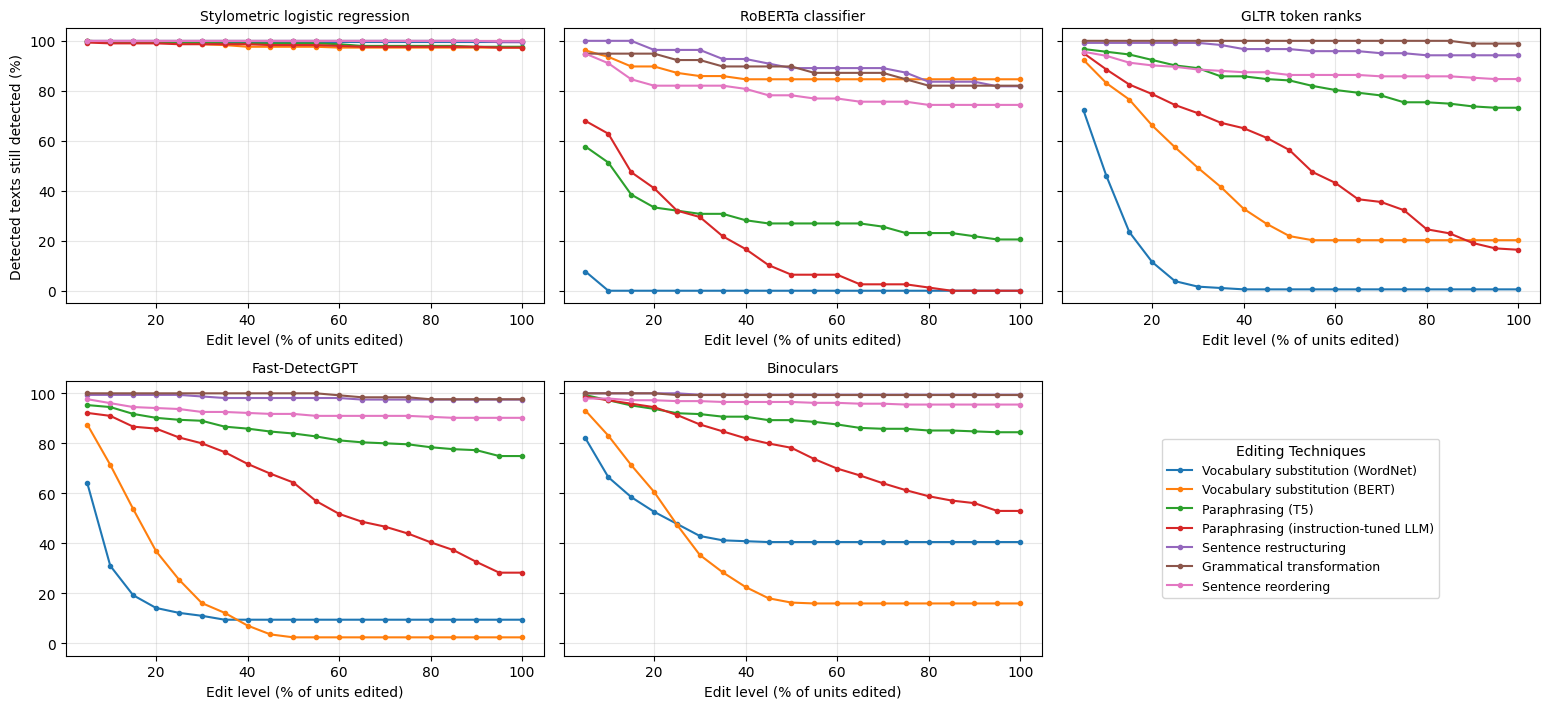

Result tables and edited samples saved to /content/drive/MyDrive/AI_Detector_Attack_Research/exports
['baseline_by_domain.csv', 'baseline_detection.csv', 'edited_samples.csv', 'failure_by_detector.csv', 'failure_by_detector_and_domain.csv', 'failure_by_detector_and_technique.csv', 'failure_records.csv', 'original_ai_samples.csv', 'rq2_group_comparison.csv', 'rq3_mean_levels_all.csv', 'rq3_mean_levels_discriminative.csv', 'rq3_permutation_pvalues_all.csv', 'rq3_permutation_pvalues_discriminative.csv', 'rq4_technique_ranking_all.csv', 'rq4_technique_ranking_discriminative.csv', 'survival_curves.csv', 'survival_curves.png']


In [ ]:
# Figures and export of every result table to Drive
if SAVE_FIGURES:
    import math
    import os
    import matplotlib.pyplot as plt

    # Filter strictly to the discriminative detectors (matches Table II in paper)
    plotted = [
        display_name[detector]
        for detector in analysis_detectors
        if detector != "phd"
    ]
    columns = min(3, len(plotted))
    rows_count = int(math.ceil((len(plotted) + 1) / columns))  # 2 rows, 3 columns

    figure, axes = plt.subplots(
        rows_count,
        columns,
        figsize=(5.2 * columns, 3.6 * rows_count),
        squeeze=False,
        sharey=True,
    )

    flat_axes = axes.ravel()

    # Plot each discriminative detector in slots 0 to 4
    for axis, detector in zip(flat_axes[: len(plotted)], plotted):
        for technique in TECHNIQUES:
            curve = survival_curves[
                (survival_curves.detector == detector)
                & (survival_curves.technique == technique)
            ]
            if len(curve):
                axis.plot(
                    curve.edit_level_pct,
                    100 * curve.share_still_detected,
                    marker="o",
                    markersize=3,
                    label=TECHNIQUE_LABELS[technique],
                )
        axis.set_title(detector, fontsize=10)
        axis.set_xlabel("Edit level (% of units edited)")
        axis.grid(alpha=0.3)

    # Use slot 5 (bottom-right) for the shared legend instead of an empty box
    legend_ax = flat_axes[-1]
    legend_ax.axis("off")
    handles, labels = flat_axes[0].get_legend_handles_labels()
    legend_ax.legend(
        handles,
        labels,
        loc="center",
        fontsize=9,
        frameon=True,
        title="Editing Techniques",
        title_fontsize=10,
    )

    axes[0][0].set_ylabel("Detected texts still detected (%)")
    figure.tight_layout()
    figure.savefig(os.path.join(EXPORT_DIR, "survival_curves.png"), dpi=300)
    plt.show()

tables = {
    "baseline_detection": baseline_table,
    "failure_by_detector": failure_pooled,
    "failure_by_detector_and_technique": failure_by_technique,
    "failure_by_detector_and_domain": failure_by_domain,
    "baseline_by_domain": domain_table,
    "survival_curves": survival_curves,
    "failure_records": failure_records.drop(columns=["detector_name"]),
    "rq2_group_comparison": group_comparison,
}

for set_key in rq4_tables:
    tables[f"rq3_mean_levels_{set_key}"] = rq3_mean_tables[
        set_key
    ].reset_index()
    tables[f"rq3_permutation_pvalues_{set_key}"] = rq3_pvalue_tables[
        set_key
    ].reset_index()
    tables[f"rq4_technique_ranking_{set_key}"] = rq4_tables[set_key]

for table_name, table in tables.items():
    table.to_csv(os.path.join(EXPORT_DIR, f"{table_name}.csv"), index=False)

print("Result tables and edited samples saved to", EXPORT_DIR)
print(sorted(os.listdir(EXPORT_DIR)))

## Notes for the methods and limitations sections
- **Detector validity.** A detector can only be "evaded" if it detects the original text. Table 1 reports AUROC with bootstrap intervals; detectors below AUROC 0.70 or with fewer than 15 detected texts are marked non-discriminative and excluded from the headline results. The reference-sample check (text generated by the detector's own model) separates a faulty implementation from a genuine lack of discrimination on this corpus.
- **Data sources.** BMAS (arXiv abstracts; CC-BY-4.0; cite Lekkala et al., 2025) and the IntelLabs peer-review benchmark (research licence; cite Yu et al., 2025) provide human and AI texts of the same domain, which removes the genre mismatch of earlier human corpora. The texts are cut to 120-350 words. Their generators are older than the newest models, and the AI texts of one domain come from one prompting protocol per dataset.
- **Calibration.** Thresholds use the calibration half of the human corpus only; false-positive rates are reported on the other half. The AI texts do not influence any threshold except for the stylometric detector, whose scores are produced by cross-validation.
- **Edit levels.** Word-level techniques are limited by the number of editable words (typically 25–35% of the words), so higher nominal levels repeat the last distinct text; sentence-level rule-based techniques can edit only the sentences that match their rules. Both are reported as the editable share in the cell that builds the payloads and through the measured edit percentage.
- **Failure definition.** A text fails at the first level (a multiple of 5) at which its detector score falls below the threshold; texts that never fail are right-censored at 100% and counted as 100% in the restricted mean.
- **LLM comparison.** Some families occur in one source only (DeepSeek in BMAS, Gemini in the peer reviews), so family and domain are partly confounded; use the "within <source>" tests in Table 6b for claims about LLM families.
- **Paraphrase LLM.** The local paraphrase model (Qwen2.5-3B-Instruct) belongs to the same vendor as one of the source families.
- **Single run.** Stochastic steps (T5 and LLM sampling, random edit order) use one fixed seed; p-values are not corrected for multiple comparisons.